# Análisis exploratorio de reportes de fenómenos aéreos no identificados (UAP), 2010–2016
## Proyecto final EDA con metodología CRISP-DM — Universidad de La Sabana, 2026-2

**Autores:** [COMPLETAR]  
**Fuente de datos:** National UFO Reporting Center (NUFORC), https://nuforc.org  
**Fecha de entrega:** 10 de noviembre de 2026

In [1]:
# Ejecutar una sola vez. En Colab, suba antes requirements.txt al mismo directorio del cuaderno.
%pip install -q -r requirements.txt

ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


Note: you may need to restart the kernel to use updated packages.


## 0. Configuración del entorno
Se cargan las librerías, se fija la semilla aleatoria (`RANDOM_STATE = 42`) para que cualquier resultado con componente aleatorio sea reproducible y se definen rutas **relativas**, de modo que el cuaderno funcione en cualquier computador. También se define una paleta de tres colores que se reutilizará en Power BI para mantener la coherencia visual.

In [2]:
# --- Librerías ---
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Reproducibilidad ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Rutas relativas ---
BASE = Path.cwd()
RAW = BASE / "data" / "raw"
PROC = BASE / "data" / "processed"
FIG = BASE / "figuras"
for carpeta in (RAW, PROC, FIG):
    carpeta.mkdir(parents=True, exist_ok=True)

# El archivo original vive SIEMPRE en data/raw (ruta relativa) y no se modifica en ningún punto.
NOMBRE_RAW = "uap-atlas-reports-2010-2100.csv"
ARCHIVO_RAW = RAW / NOMBRE_RAW
if not ARCHIVO_RAW.exists() and (BASE / NOMBRE_RAW).exists():      # archivo suelto junto al cuaderno (p. ej., Colab)
    shutil.copy(BASE / NOMBRE_RAW, ARCHIVO_RAW)
assert ARCHIVO_RAW.exists(), f"Copie el archivo original en: {ARCHIVO_RAW}"

# --- Estilo gráfico (misma paleta que el tablero de Power BI) ---
AZUL, AMBAR, GRIS = "#1F3A5F", "#F2A541", "#8C8C8C"
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def guardar_fig(nombre):
    """Guarda la figura actual en /figuras (para el informe APA) y la muestra."""
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__)
print("Carpeta de trabajo:", BASE)

pandas 2.2.3 | numpy 2.5.3
Carpeta de trabajo: /home/claude/nbrun


---
# FASE 1. Comprensión del negocio

### 1.1 Temática y pertinencia
El proyecto analiza 50.000 reportes ciudadanos de fenómenos aéreos no identificados (UAP, por sus siglas en inglés) recibidos por el National UFO Reporting Center (NUFORC) entre 2010 y 2016. El tema dejó de ser marginal: la Oficina del Director de Inteligencia Nacional de EE. UU. (ODNI, 2021) y la NASA (2023) reconocieron que la mayor limitación para entender estos fenómenos es la **calidad y la gestión de los datos de reporte**, no la falta de reportes. 

**Supuesto de partida.** No se tuvo acceso a los objetivos, procesos ni capacidad operativa reales de NUFORC (ni de ninguna otra organización que registre estos reportes). Por eso los objetivos de negocio de este proyecto **no son los de NUFORC: son objetivos supuestos**, formulados desde la perspectiva de un analista externo que se pone en el lugar de un centro de recepción hipotético que recibe miles de reportes al año y necesita saber cuántos llegarán y cuándo, para no saturar a sus analistas ni dejar reportes sin revisar. Esta decisión se mantiene como limitación explícita (sección 5.4).

**Delimitación:** el análisis no busca determinar el origen de los fenómenos. Estudia el **comportamiento del proceso de reporte** (volumen, momento, lugar, forma y duración declaradas).

### 1.2 Objetivos de negocio (supuestos) y su traducción analítica

| Objetivo de negocio (supuesto) | Objetivo analítico | Pregunta | Técnica |
|---|---|---|---|
| ON1. Asignar analistas según la carga esperada en cada periodo | Describir la variación del volumen por año, mes, día de la semana y hora | P1 | EDA temporal, mapa de calor hora × día |
| ON2. Priorizar y clasificar los reportes que llegan | Caracterizar las formas reportadas y su relación con la duración y la hora | P2 | Kruskal-Wallis, χ² y V de Cramér |
| ON3. Planear la capacidad con anticipación | Pronosticar el volumen mensual (y semanal) de reportes | P3 | Series de tiempo: ingenuo estacional, SARIMA/Holt-Winters, Random Forest |
| ON4. Prepararse para los días de alta demanda | Verificar si hay picos en festivos con pirotecnia | Hipótesis H1 | Comparación de conteos diarios y prueba χ² |

**¿Por qué la técnica central es el pronóstico de series de tiempo?** Al no existir un objetivo operativo definido por la organización, el único objetivo que los propios datos permiten **definir y medir** es la demanda en el tiempo: el volumen de reportes. Las demás variables no ofrecen una variable objetivo defendible: `status` es casi constante (99,97 % *open*) y, como se verá en la fase 2, `shape` y `durationSec` tienen relaciones débiles con el resto de variables. Por eso no se usan los modelos más conocidos de clasificación o de regresión transversal, y el modelo del proyecto es un pronóstico de series de tiempo.

### 1.3 Preguntas de análisis
- **P1.** ¿Cómo varía el volumen de reportes según el año, el mes, el día de la semana y la hora?
- **P2.** ¿Qué formas predominan y cómo se relacionan con la duración y la hora del avistamiento?
- **P3.** ¿Es posible pronosticar el volumen mensual o semanal de reportes con un error útil para planear la operación?
- **H1.** El 4 de julio y el Año Nuevo (31 de diciembre y 1 de enero) concentran picos de reportes, con mayor proporción de formas *fireball* y *light*, asociadas a fuegos artificiales y linternas chinas.

### 1.4 Criterios de éxito (medibles)
| Código | Criterio | Umbral | Se evalúa en |
|---|---|---|---|
| CE1 | MAPE del mejor modelo en el conjunto de prueba (2016) | ≤ 20 % (ideal ≤ 15 %) | Fase 5 |
| CE2 | Reducción del MAE frente al ingenuo estacional | ≥ 10 % | Fase 5 |
| CE3 | Residuos del modelo principal sin autocorrelación | Ljung-Box, p > 0,05 | Fase 4 |
| CE4 | P1, P2 y H1 respondidas con evidencia estadística | Prueba y tamaño de efecto reportados | Fases 2 y 6 |
| CE5 | Tablero que responda P1–P3 con filtros e interactividad | 5 páginas, ≥ 5 tipos de visual | Fase 6 |

**Interpretación operativa de CE1:** con un MAPE de 20 %, si el pronóstico indica 500 reportes en un mes, el valor real estaría en promedio entre 400 y 600; ese margen es suficiente para decidir cuántos analistas asignar.

### 1.5 Plan del proyecto según CRISP-DM
| Fase | Actividades | Entregable | Herramienta |
|---|---|---|---|
| 1. Comprensión del negocio | Objetivos, preguntas, criterios de éxito | Sección 1 del cuaderno e informe | Markdown |
| 2. Comprensión de los datos | Documentación de la fuente, calidad, EDA univariado y bivariado | Figuras 1–9, tablas de calidad | pandas, scipy, seaborn |
| 3. Preparación (ETL) | Limpieza, imputación, ingeniería de variables, registro de cambios, exportación | `data/processed/*.csv`, diccionario de datos | pandas, reverse_geocoder |
| 4. Modelado | Series mensual y semanal, ADF, ACF/PACF, ingenuo estacional, SARIMA/Holt-Winters, Random Forest | Modelos ajustados, diagnóstico de residuos | statsmodels, scikit-learn |
| 5. Evaluación | MAE, RMSE, MAPE; contraste con CE1–CE3; limitaciones | Tabla de métricas, `metricas_modelo.csv` | pandas |
| 6. Despliegue | Modelo en estrella, medidas DAX, tablero de 5 páginas | Archivo `.pbix`, informe APA, sustentación | Power BI |

---
# FASE 2. Comprensión de los datos

## 2.1 Extracción y documentación de la fuente

| Metadato | Valor |
|---|---|
| Organización | National UFO Reporting Center (NUFORC), organización sin ánimo de lucro con sede en EE. UU., activa desde 1974 |
| Sitio web | https://nuforc.org |
| URL exacta de descarga del archivo | [COMPLETAR: enlace exacto del CSV]. Compilación de origen: UFOSINT, *ufo-dedup* (https://github.com/UFOSINT/ufo-dedup), que importa los reportes de NUFORC directamente |
| Fecha de acceso / descarga | [COMPLETAR] |
| Archivo | `uap-atlas-reports-2010-2100.csv` (UTF-8, separador coma) |
| Periodo real cubierto | 2010-01-01 a 2017-01-18 (el nombre dice 2010–2100, pero no es así; se verifica abajo) |
| Unidad de observación | Un reporte ciudadano de avistamiento |
| Volumen | 50.000 filas × 11 columnas |
| Forma de recolección | Reporte voluntario en línea o telefónico; los campos de forma y duración los declara quien reporta |

**Confiabilidad:** NUFORC es la base pública de reportes UAP más usada en la literatura y cada registro conserva su enlace al reporte original (`sourceUrl`), lo que permite auditarlo. Sin embargo, los datos son **auto-reportados**: describen percepciones, no fenómenos verificados. Esta limitación condiciona todo el análisis y se retoma en la evaluación.

In [3]:
# Carga del dataset ORIGINAL. df_raw no se modifica en ningún punto del cuaderno.
df_raw = pd.read_csv(ARCHIVO_RAW, encoding="utf-8")
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones: 50,000 filas x 11 columnas


,id,source,datetime,lat,lng,shape,durationSec,country,locationPrecision,status,sourceUrl
0,nuforc-0b4724e3626d66dc,nuforc,2010-01-01,38.620,-90.190,fireball,60.000,USA,city,open,https://nuforc.org/sighting/?id=73908
1,nuforc-6263f487a670e409,nuforc,2010-01-01,37.090,-86.040,orb,2.000,USA,city,open,https://nuforc.org/sighting/?id=73909
2,nuforc-b9dae8df80141a68,nuforc,2010-01-01,32.790,-116.960,triangle,360.000,USA,city,open,https://nuforc.org/sighting/?id=73913
3,nuforc-56f8bed02f0973a5,nuforc,2010-01-01,32.760,-117.020,light,600.000,USA,city,open,https://nuforc.org/sighting/?id=73915
4,nuforc-4ab87d68057be267,nuforc,2010-01-01,32.740,-117.030,light,900.000,USA,city,open,https://nuforc.org/sighting/?id=73916


In [4]:
# Diccionario inicial de las 11 variables (antes de cualquier transformación)
descripciones = {
    "id": "Identificador único del reporte en el atlas",
    "source": "Fuente del reporte",
    "datetime": "Fecha y hora local del avistamiento (ISO 8601; a veces solo fecha)",
    "lat": "Latitud de la ciudad del reporte (grados decimales)",
    "lng": "Longitud de la ciudad del reporte (grados decimales)",
    "shape": "Forma del objeto declarada por quien reporta",
    "durationSec": "Duración declarada del avistamiento, en segundos",
    "country": "País (código ISO 3166-1 alfa-3)",
    "locationPrecision": "Nivel de precisión de la ubicación",
    "status": "Estado de revisión del reporte",
    "sourceUrl": "Enlace al reporte original en nuforc.org",
}
tipo_conceptual = {
    "id": "Identificador", "source": "Categórica nominal", "datetime": "Fecha/hora",
    "lat": "Cuantitativa continua", "lng": "Cuantitativa continua", "shape": "Categórica nominal",
    "durationSec": "Cuantitativa continua (razón)", "country": "Categórica nominal",
    "locationPrecision": "Categórica nominal", "status": "Categórica nominal", "sourceUrl": "Identificador",
}
dicc_inicial = pd.DataFrame({
    "variable": df_raw.columns,
    "tipo_pandas": df_raw.dtypes.astype(str).values,
    "tipo_conceptual": [tipo_conceptual[c] for c in df_raw.columns],
    "descripcion": [descripciones[c] for c in df_raw.columns],
    "ejemplo": [df_raw[c].dropna().iloc[0] for c in df_raw.columns],
    "valores_unicos": df_raw.nunique().values,
})
dicc_inicial

,variable,tipo_pandas,tipo_conceptual,descripcion,ejemplo,valores_unicos
0,id,object,Identificador,Identificador único del reporte en el atlas,nuforc-0b4724e3626d66dc,50000
1,source,object,Categórica nominal,Fuente del reporte,nuforc,1
2,datetime,object,Fecha/hora,Fecha y hora local del avistamiento (ISO 8601;...,2010-01-01,40191
3,lat,float64,Cuantitativa continua,Latitud de la ciudad del reporte (grados decim...,38.620,3226
4,lng,float64,Cuantitativa continua,Longitud de la ciudad del reporte (grados deci...,-90.190,5570
5,shape,object,Categórica nominal,Forma del objeto declarada por quien reporta,fireball,24
6,durationSec,float64,Cuantitativa continua (razón),"Duración declarada del avistamiento, en segundos",60.000,174
7,country,object,Categórica nominal,País (código ISO 3166-1 alfa-3),USA,111
8,locationPrecision,object,Categórica nominal,Nivel de precisión de la ubicación,city,1
9,status,object,Categórica nominal,Estado de revisión del reporte,open,3


## 2.2 Verificación inicial de la calidad
Se revisan volumen, tipos de dato, faltantes, rangos, variables constantes, duplicados y categorías que funcionan como faltantes. **En esta fase solo se diagnostica; los tratamientos se aplican en la fase 3.**

In [5]:
# --- Faltantes y tipos ---
calidad = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "no_nulos": df_raw.notna().sum(),
    "nulos": df_raw.isna().sum(),
    "pct_nulos": (df_raw.isna().mean() * 100).round(2),
    "valores_unicos": df_raw.nunique(),
})
calidad["constante"] = calidad["valores_unicos"] == 1
calidad.sort_values("nulos", ascending=False)

,tipo,no_nulos,nulos,pct_nulos,valores_unicos,constante
durationSec,float64,42289,7711,15.420,174,False
country,object,48557,1443,2.890,111,False
shape,object,49007,993,1.990,24,False
datetime,object,50000,0,0.000,40191,False
source,object,50000,0,0.000,1,True
id,object,50000,0,0.000,50000,False
lng,float64,50000,0,0.000,5570,False
lat,float64,50000,0,0.000,3226,False
locationPrecision,object,50000,0,0.000,1,True
status,object,50000,0,0.000,3,False


In [6]:
# --- Rangos de las variables numéricas y validez geográfica ---
rangos = df_raw[["lat", "lng", "durationSec"]].describe().T
rangos["fuera_de_rango"] = [
    ((df_raw["lat"] < -90) | (df_raw["lat"] > 90)).sum(),
    ((df_raw["lng"] < -180) | (df_raw["lng"] > 180)).sum(),
    (df_raw["durationSec"] <= 0).sum(),
]
display(rangos)
print("Duraciones > 24 h (86.400 s):", (df_raw["durationSec"] > 86_400).sum())

,count,mean,std,min,25%,50%,75%,max,fuera_de_rango
lat,"50,000.000",38.099,8.778,-46.630,34.100,39.320,42.460,70.420,0
lng,"50,000.000",-88.928,33.034,-170.480,-111.830,-86.780,-78.860,178.420,0
durationSec,"42,289.000",542.048,"2,742.986",1.000,40.000,180.000,600.000,"300,600.000",0


Duraciones > 24 h (86.400 s): 11


In [7]:
# --- Fechas: formato, rango real y registros sin hora ---
fecha = pd.to_datetime(df_raw["datetime"], format="ISO8601")
solo_fecha = ~df_raw["datetime"].str.contains("T")      # '2010-01-01' frente a '2010-01-01T20:00:00'
print("Fecha mínima:", fecha.min(), "| Fecha máxima:", fecha.max())
print(f"Registros solo con fecha (sin hora): {solo_fecha.sum():,} ({solo_fecha.mean():.1%})")

por_anio = fecha.dt.year.value_counts().sort_index().rename("reportes").to_frame()
por_anio["completo"] = np.where(por_anio.index == 2017, "NO (hasta 18-ene)", "sí")
por_anio

Fecha mínima: 2010-01-01 00:00:00 | Fecha máxima: 2017-01-18 01:00:00
Registros solo con fecha (sin hora): 1,624 (3.2%)


,reportes,completo
datetime,,
2010,5028,sí
2011,5960,sí
2012,8398,sí
2013,8053,sí
2014,9011,sí
2015,7272,sí
2016,6081,sí
2017,197,NO (hasta 18-ene)


In [8]:
# --- Variables constantes, identificadores y 'status' ---
for col in ["source", "locationPrecision"]:
    print(f"{col}: {df_raw[col].unique().tolist()}")
print("\nid único por fila:", df_raw["id"].is_unique, "| sourceUrl único:", df_raw["sourceUrl"].is_unique)
print("\nDistribución de status:")
display(df_raw["status"].value_counts().to_frame("n").assign(pct=lambda t: (t["n"] / len(df_raw) * 100).round(3)))

source: ['nuforc']
locationPrecision: ['city']

id único por fila: True | sourceUrl único: True

Distribución de status:


,n,pct
status,,
open,49985,99.970
explained,14,0.028
hoax,1,0.002


In [9]:
# --- Categorías que funcionan como faltantes en 'shape' ---
pseudo_nulos = df_raw["shape"].isin(["unknown", "other"])
print(f"shape nulo: {df_raw['shape'].isna().sum():,} | 'unknown': {(df_raw['shape']=='unknown').sum():,} "
      f"| 'other': {(df_raw['shape']=='other').sum():,}")
sin_forma = df_raw["shape"].isna() | pseudo_nulos
print(f"Total sin forma informativa: {sin_forma.sum():,} ({sin_forma.mean():.1%})")
print("Categorías de shape:", df_raw["shape"].nunique(), "| raras (<30 casos):",
      df_raw["shape"].value_counts()[lambda s: s < 30].to_dict())

# --- Posibles duplicados ---
claves = ["datetime", "lat", "lng", "shape"]
dup = df_raw.duplicated(claves, keep="first")
print(f"\nPosibles duplicados por {claves}: {dup.sum():,} "
      f"(filas involucradas: {df_raw.duplicated(claves, keep=False).sum():,})")
print("Duplicados exactos en todas las columnas salvo id/sourceUrl:",
      df_raw.drop(columns=["id", "sourceUrl"]).duplicated().sum())

shape nulo: 993 | 'unknown': 3,375 | 'other': 3,041
Total sin forma informativa: 7,409 (14.8%)
Categorías de shape: 24 | raras (<30 casos): {'star': 7, 'cube': 2}

Posibles duplicados por ['datetime', 'lat', 'lng', 'shape']: 439 (filas involucradas: 860)
Duplicados exactos en todas las columnas salvo id/sourceUrl: 320


### Síntesis de la calidad inicial y suficiencia de los datos

| Problema detectado | Magnitud | Tratamiento previsto (fase 3) |
|---|---|---|
| Nombre engañoso: el archivo dice 2010–2100 | Datos reales: 2010-01-01 a 2017-01-18 | Documentar; usar 2010–2016 |
| 2017 incompleto | 197 registros (18 días) | Excluir de análisis anuales y del modelo |
| `source`, `locationPrecision` constantes; `id`, `sourceUrl` identificadores | 4 columnas | Eliminar del análisis (conservar `id` como llave) |
| `status` casi constante | 49.985 *open*, 14 *explained*, 1 *hoax* | Descartar como variable objetivo |
| Faltantes en `durationSec` | 7.711 (15,4 %) | Imputar con mediana por forma + marca de faltante |
| Faltantes en `country` | 1.443 (2,9 %) | Imputar desde lat/lng (geocodificación inversa) |
| Faltantes en `shape` + *unknown* + *other* | 993 + 3.375 + 3.041 = 7.409 (14,8 %) | Unificar en "desconocida" |
| `datetime` sin hora | 1.624 (3,2 %) | Marca `hora_conocida`; excluir del análisis por hora |
| Duración muy asimétrica, con valores extremos | máx. 300.600 s; 11 casos > 24 h | Umbral de 24 h y escala logarítmica |
| Posibles duplicados | 439 | Revisar y decidir en la fase 3 |

**¿Permiten estos datos responder las preguntas?** Sí. (a) `datetime` está completo en las 50.000 filas, lo que permite agregar por año, mes, día y hora (**P1**) y construir series mensuales y semanales de 84 meses y unas 365 semanas, suficientes para estimar estacionalidad anual (**P3**). (b) `shape` y `durationSec` cubren cerca del 85 % de los registros, suficiente para comparar formas (**P2**). (c) `lat` y `lng` no tienen faltantes, lo que permite el análisis geográfico y recuperar el país faltante. La limitación principal no es de volumen sino de **representatividad**: los reportes son voluntarios y se concentran en EE. UU.

In [10]:
# Copia de trabajo SOLO para el EDA (no es el dataset procesado; ese se construye en la fase 3).
eda = df_raw.copy()
eda["fecha_hora"] = fecha
eda["hora_conocida"] = ~solo_fecha
eda["anio"] = eda["fecha_hora"].dt.year
eda["mes"] = eda["fecha_hora"].dt.month
eda["dia_semana"] = eda["fecha_hora"].dt.dayofweek            # 0 = lunes ... 6 = domingo
# Hora solo cuando se conoce: de lo contrario los 1.624 registros sin hora crearían un pico falso a las 00:00
eda["hora"] = eda["fecha_hora"].dt.hour.where(eda["hora_conocida"]).astype("Int64")
eda["log_duracion"] = np.log10(eda["durationSec"])           # log10: 1 = 10 s, 2 = 100 s, 3 ≈ 17 min
eda["forma_eda"] = eda["shape"].replace({"unknown": np.nan, "other": np.nan})

eda16 = eda[eda["anio"] <= 2016].copy()                        # años completos para análisis temporales
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
print(f"Registros 2010–2016: {len(eda16):,} | con hora conocida: {eda16['hora_conocida'].sum():,}")

Registros 2010–2016: 49,803 | con hora conocida: 48,185


## 2.3 Análisis exploratorio univariado

### 2.3.1 Duración del avistamiento (variable cuantitativa)

In [11]:
def resumen_numerico(s):
    """Medidas de tendencia central, dispersión y forma para una variable cuantitativa."""
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "n": len(s), "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
        "desv_estandar": s.std(), "coef_variacion": s.std() / s.mean(),
        "minimo": s.min(), "Q1": q1, "Q3": q3, "IQR": q3 - q1, "maximo": s.max(),
        "asimetria": stats.skew(s), "curtosis_exceso": stats.kurtosis(s),
    })

tabla_duracion = pd.DataFrame({
    "durationSec (s)": resumen_numerico(eda["durationSec"]),
    "log10(durationSec)": resumen_numerico(eda["log_duracion"]),
})
display(tabla_duracion)

# Atípicos por regla de Tukey (1,5 × IQR) en ambas escalas
def n_atipicos(s):
    s = s.dropna(); q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
print("Atípicos Tukey, escala cruda:", n_atipicos(eda["durationSec"]),
      "| escala log:", n_atipicos(eda["log_duracion"]))

# Redondeo de las estimaciones: ¿qué proporción son múltiplos de 60 s?
dur = eda["durationSec"].dropna()
print(f"Duraciones múltiplo de 60 s: {(dur % 60 == 0).mean():.1%}")
print("Valores más frecuentes (s):", dur.value_counts().head(6).to_dict())

,durationSec (s),log10(durationSec)
n,"42,289.000","42,289.000"
media,542.048,2.111
mediana,180.000,2.255
moda,300.000,2.477
desv_estandar,"2,742.986",0.844
coef_variacion,5.060,0.400
minimo,1.000,0.000
Q1,40.000,1.602
Q3,600.000,2.778
IQR,560.000,1.176


Atípicos Tukey, escala cruda: 4026 | escala log: 12
Duraciones múltiplo de 60 s: 72.2%
Valores más frecuentes (s): {300.0: 5549, 120.0: 4186, 60.0: 3953, 600.0: 3423, 180.0: 3242, 900.0: 2145}


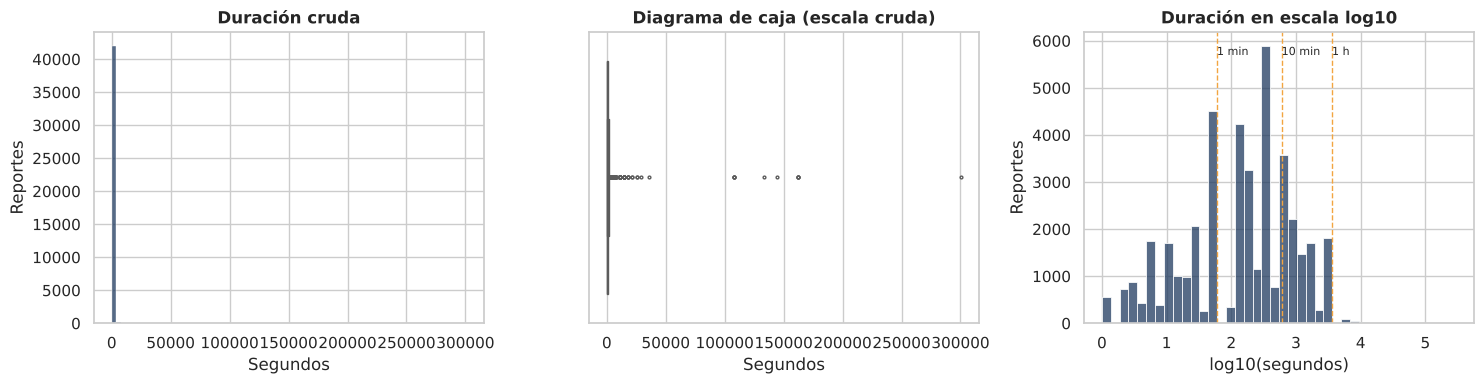

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(eda["durationSec"].dropna(), bins=80, color=AZUL, ax=ax[0])
ax[0].set(title="Duración cruda", xlabel="Segundos", ylabel="Reportes")
sns.boxplot(x=eda["durationSec"].dropna(), color=AMBAR, ax=ax[1], fliersize=2)
ax[1].set(title="Diagrama de caja (escala cruda)", xlabel="Segundos")
sns.histplot(eda["log_duracion"].dropna(), bins=40, color=AZUL, ax=ax[2])
for v, etq in [(np.log10(60), "1 min"), (np.log10(600), "10 min"), (np.log10(3600), "1 h")]:
    ax[2].axvline(v, color=AMBAR, ls="--", lw=1); ax[2].text(v, ax[2].get_ylim()[1] * 0.92, etq, fontsize=8)
ax[2].set(title="Duración en escala log10", xlabel="log10(segundos)", ylabel="Reportes")
guardar_fig("fig01_distribucion_duracion")

**Interpretación (Figura 1).** La duración cruda tiene una media de 542 s, tres veces la mediana (180 s), un coeficiente de variación de 5,1, una asimetría de 62,3 y una curtosis de exceso de 5.050: unos pocos reportes de horas o días arrastran la media, y la regla de Tukey marca 4.026 atípicos en escala cruda pero solo 12 en escala log. Por eso **la media no representa al reporte típico** y no debe usarse para imputar; en la fase 3 se imputará con la mediana por forma. En escala log10 la distribución es aproximadamente simétrica (asimetría −0,43; curtosis −0,37; mediana 2,26 ≈ 3 min), lo que justifica crear `log_duracion` para comparar formas. Además, el 72,2 % de las duraciones son múltiplos de 60 s y los cuatro valores más frecuentes son 300, 120, 60 y 600 s: son estimaciones redondeadas de quien reporta, así que la duración debe leerse como un **orden de magnitud** y conviene complementarla con una variable por rangos (`rango_duracion`).

### 2.3.2 Variables categóricas

Moda de shape: light


,n,pct,pct_acum
shape,,,
light,9647,19.294,19.294
circle,5325,10.650,29.944
fireball,5267,10.534,40.478
triangle,4370,8.740,49.218
unknown,3375,6.750,55.968
other,3041,6.082,62.050
sphere,2694,5.388,67.438
orb,2612,5.224,72.662
oval,2090,4.180,76.842


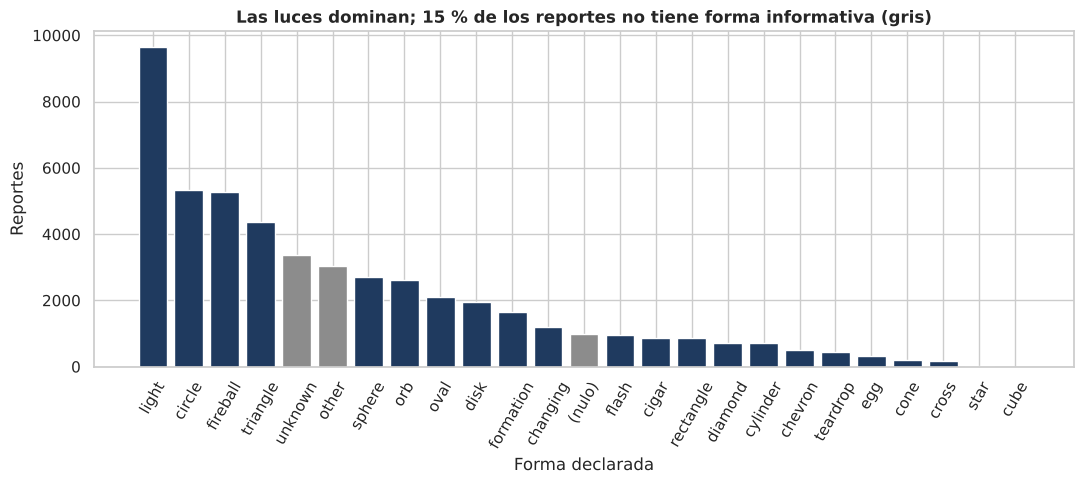

In [13]:
# Frecuencias de shape (incluidos los nulos para que se vea el problema)
freq_forma = (eda["shape"].fillna("(nulo)").value_counts().to_frame("n")
              .assign(pct=lambda t: t["n"] / t["n"].sum() * 100,
                      pct_acum=lambda t: t["pct"].cumsum()))
print("Moda de shape:", eda["shape"].mode().iloc[0])
display(freq_forma)

fig, ax = plt.subplots(figsize=(11, 5))
colores = [GRIS if f in ("(nulo)", "unknown", "other") else AZUL for f in freq_forma.index]
ax.bar(freq_forma.index, freq_forma["n"], color=colores)
ax.set(title="Las luces dominan; 15 % de los reportes no tiene forma informativa (gris)",
       xlabel="Forma declarada", ylabel="Reportes")
ax.tick_params(axis="x", rotation=60)
guardar_fig("fig02_frecuencia_formas")

In [14]:
# Frecuencias de país y status
freq_pais = (eda["country"].fillna("(nulo)").value_counts().to_frame("n")
             .assign(pct=lambda t: t["n"] / t["n"].sum() * 100))
print("Países distintos:", eda["country"].nunique(), "| moda:", eda["country"].mode().iloc[0])
display(freq_pais.head(10))
print("Índice de concentración de Herfindahl-Hirschman (países):",
      round(((eda["country"].value_counts(normalize=True)) ** 2).sum(), 3))

Países distintos: 111 | moda: USA


,n,pct
country,,
USA,44990,89.980
CAN,1678,3.356
(nulo),1443,2.886
GBR,565,1.130
AUS,168,0.336
IND,161,0.322
MEX,76,0.152
ZAF,66,0.132
DEU,36,0.072


Índice de concentración de Herfindahl-Hirschman (países): 0.86


**Interpretación (Figura 2 y tabla de países).** La moda es *light* (19 % de los reportes) y las cinco formas más frecuentes (*light, circle, fireball, triangle, sphere*) suman más de la mitad, mientras que *star* y *cube* tienen menos de 10 casos: con tan pocos datos no se puede estimar nada sobre ellas, lo que justifica agrupar las 24 formas en unos seis grupos (`grupo_forma`). El 15 % sin forma informativa (nulo, *unknown*, *other*) es demasiado para eliminarlo y se tratará como la categoría "desconocida". En geografía, el 90 % de los reportes son de EE. UU. y el índice de Herfindahl-Hirschman es 0,86 (concentración extrema; 1 sería un solo país): **las conclusiones y el pronóstico describen, en la práctica, el proceso de reporte estadounidense**, y en el tablero se mostrarán los demás países solo como contexto. `status` no se grafica: con 99,97 % de *open* no tiene variabilidad que analizar.

### 2.3.3 Distribución temporal

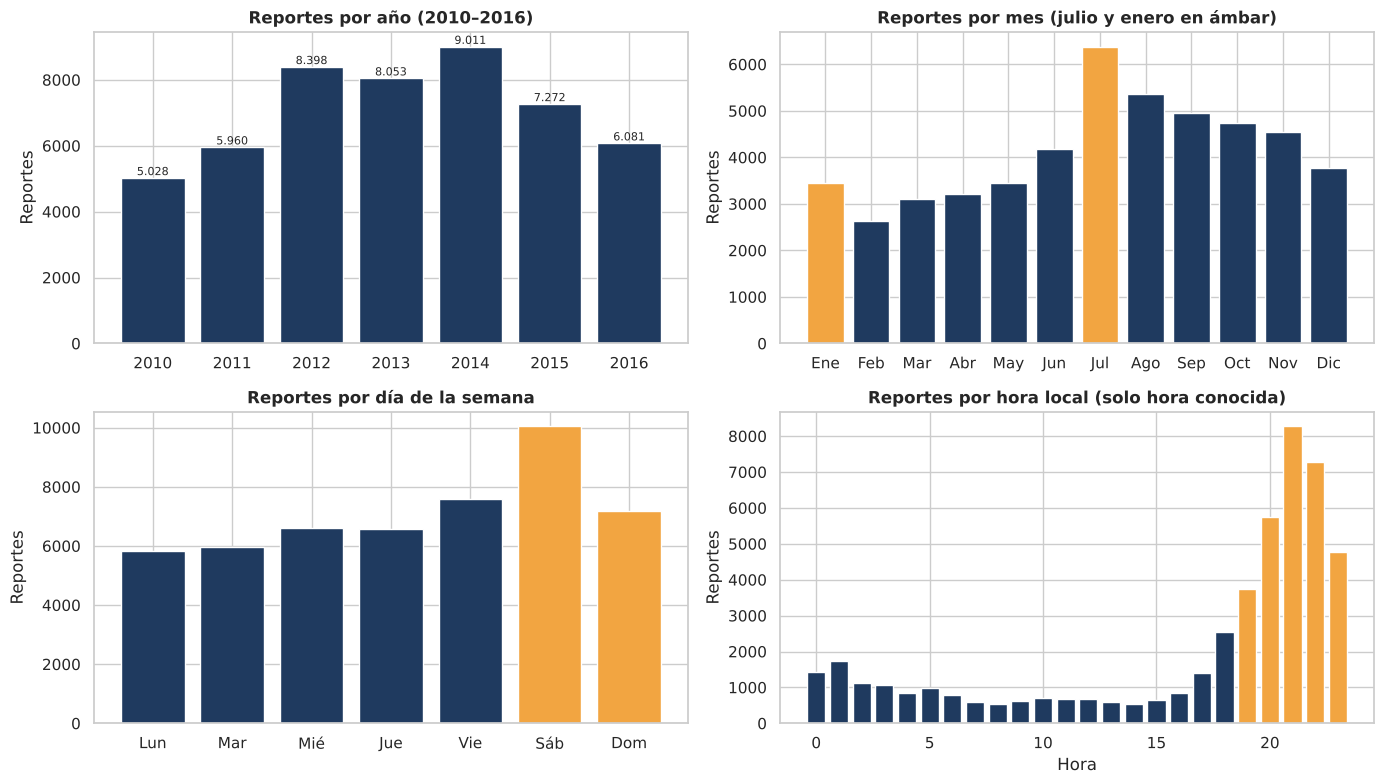

,valor
variacion_anual_max_min,1.792
mes_pico,Jul
razon_mes_pico_vs_minimo,2.431
dia_pico,Sáb
pct_fin_de_semana,34.572
hora_pico,21
pct_19_a_23h,61.830


In [15]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))

anual = eda16["anio"].value_counts().sort_index()
ax[0, 0].bar(anual.index.astype(str), anual.values, color=AZUL)
ax[0, 0].set(title="Reportes por año (2010–2016)", ylabel="Reportes")
for x, y in zip(anual.index.astype(str), anual.values):
    ax[0, 0].text(x, y, f"{y:,}".replace(",", "."), ha="center", va="bottom", fontsize=8)

mensual = eda16["mes"].value_counts().sort_index()
ax[0, 1].bar(MESES, mensual.values, color=[AMBAR if m in (7, 1) else AZUL for m in mensual.index])
ax[0, 1].set(title="Reportes por mes (julio y enero en ámbar)", ylabel="Reportes")

semanal = eda16["dia_semana"].value_counts().sort_index()
ax[1, 0].bar(DIAS, semanal.values, color=[AMBAR if d >= 5 else AZUL for d in semanal.index])
ax[1, 0].set(title="Reportes por día de la semana", ylabel="Reportes")

horaria = eda16["hora"].dropna().astype(int).value_counts().sort_index()
ax[1, 1].bar(horaria.index, horaria.values, color=[AMBAR if 19 <= h <= 23 else AZUL for h in horaria.index])
ax[1, 1].set(title="Reportes por hora local (solo hora conocida)", xlabel="Hora", ylabel="Reportes")
guardar_fig("fig03_distribucion_temporal")

resumen_t = {
    "variacion_anual_max_min": anual.max() / anual.min(),
    "mes_pico": MESES[mensual.idxmax() - 1], "razon_mes_pico_vs_minimo": mensual.max() / mensual.min(),
    "dia_pico": DIAS[semanal.idxmax()], "pct_fin_de_semana": eda16["dia_semana"].ge(5).mean() * 100,
    "hora_pico": int(horaria.idxmax()), "pct_19_a_23h": horaria.loc[19:23].sum() / horaria.sum() * 100,
}
pd.Series(resumen_t, name="valor").to_frame()

**Interpretación (Figura 3) — responde P1.** El volumen anual no es estable: crece de 5.028 reportes en 2010 a 9.011 en 2014 (+79 %) y luego cae a 7.272 en 2015 y 6.081 en 2016. La tendencia **no es monótona**, así que un modelo que extrapole la pendiente de 2010–2014 sobreestimaría 2016; este es el principal riesgo para el pronóstico de la fase 4. Por mes, el pico está en julio (6.383) y es 2,4 veces febrero, el mes más bajo, lo que anticipa una **estacionalidad anual (período 12)** que exige un modelo estacional y hace del ingenuo estacional una referencia exigente. Por hora, entre las 19:00 y las 23:00 se concentra el 61,8 % de los reportes con hora conocida, con pico a las 21:00: los avistamientos son un fenómeno nocturno y la demanda de revisión llega en las horas siguientes, lo que orienta los turnos. El sábado es el día pico y el fin de semana reúne el 34,6 % de los reportes, frente al 28,6 % (2/7) que se esperaría si todos los días fueran iguales: un efecto moderado frente al de la hora y el mes.

## 2.4 Análisis exploratorio bivariado

### 2.4.1 Duración según la forma: diagramas de caja y prueba de Kruskal-Wallis
Se usan pruebas **no paramétricas** porque la duración no es normal ni siquiera en escala log (valores redondeados, colas largas). Se excluyen los reportes sin forma informativa y las formas con menos de 30 casos (*star*, *cube*), cuya mediana no sería estable.

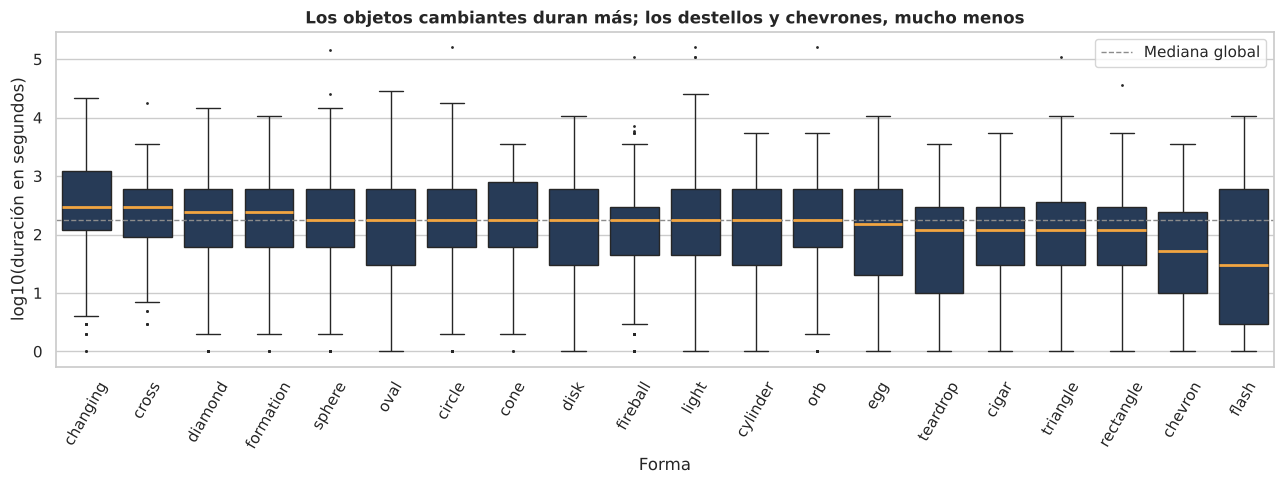

Kruskal-Wallis: H = 689.3, gl = 19, p = 6.77e-134, η²_H = 0.018  (n = 36,445)


,n,mediana_s,Q1,Q3
forma_eda,,,,
changing,964,300.000,120.000,"1,200.000"
cross,141,300.000,90.000,600.000
diamond,591,240.000,60.000,600.000
formation,1468,240.000,60.000,600.000
sphere,2371,180.000,60.000,600.000
oval,1770,180.000,30.000,600.000
circle,4412,180.000,60.000,600.000
cone,165,180.000,60.000,780.000
disk,1537,180.000,30.000,600.000


In [16]:
base_box = eda.dropna(subset=["forma_eda", "log_duracion"])
conteo = base_box["forma_eda"].value_counts()
base_box = base_box[base_box["forma_eda"].isin(conteo[conteo >= 30].index)]
orden = base_box.groupby("forma_eda")["log_duracion"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=base_box, x="forma_eda", y="log_duracion", order=orden, color=AZUL,
            fliersize=1, medianprops={"color": AMBAR, "lw": 2}, ax=ax)
ax.axhline(base_box["log_duracion"].median(), color=GRIS, ls="--", lw=1, label="Mediana global")
ax.set(title="Los objetos cambiantes duran más; los destellos y chevrones, mucho menos",
       xlabel="Forma", ylabel="log10(duración en segundos)")
ax.tick_params(axis="x", rotation=60); ax.legend()
guardar_fig("fig04_boxplot_duracion_forma")

# Prueba de Kruskal-Wallis y tamaño del efecto (eta cuadrado basado en H; Tomczak y Tomczak, 2014)
grupos = [g["log_duracion"].values for _, g in base_box.groupby("forma_eda")]
H, p_kw = stats.kruskal(*grupos)
k, n = len(grupos), len(base_box)
eta2_H = (H - k + 1) / (n - k)
print(f"Kruskal-Wallis: H = {H:,.1f}, gl = {k-1}, p = {p_kw:.2e}, η²_H = {eta2_H:.3f}  (n = {n:,})")

mediana_forma = (base_box.groupby("forma_eda")["durationSec"]
                 .agg(n="size", mediana_s="median", Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75))
                 .sort_values("mediana_s", ascending=False))
mediana_forma

**Interpretación (Figura 4) — responde P2.** La prueba de Kruskal-Wallis rechaza que las 20 formas tengan la misma distribución de duración (H = 689,3; gl = 19; p < 0,001), pero el tamaño del efecto es muy pequeño (η²_H = 0,018, frente a 0,01 «pequeño», 0,06 «mediano» y 0,14 «grande»: la forma explica menos del 2 % de la variación en el rango de la duración): con 40.000 reportes cualquier diferencia resulta significativa, de modo que la decisión se basa en el **tamaño del efecto**, no en el valor p. Los extremos sí son claros y tienen sentido: *flash* (mediana 30 s) y *chevron* (52,5 s) son eventos breves, compatibles con meteoros o destellos, mientras que *changing* (300 s, Q3 de 20 min) se reporta como un fenómeno prolongado; la mayoría de las formas comparten una mediana de 180 s. **Decisión para la fase 3:** aunque el efecto global es pequeño, las medianas de los extremos difieren hasta 10 veces, así que los faltantes de `durationSec` se imputarán con la **mediana de su forma** y no con una mediana global.

### 2.4.2 Forma según la franja horaria: tabla de contingencia, χ² y V de Cramér

χ² = 2,287.5, gl = 57, p = 0.00e+00, V de Cramér = 0.136 (n = 41,140)
Celdas con frecuencia esperada < 5: 0.0% (debe ser < 20 %)


franja,Madrugada (0–5),Mañana (6–11),Tarde (12–17),Noche (18–23)
forma_eda,,,,
fireball,10.100,5.500,4.400,80.100
formation,12.000,5.600,7.400,75.000
light,15.400,6.200,4.800,73.600
orb,13.100,6.200,7.800,73.000
chevron,16.000,5.100,9.700,69.100
triangle,16.500,7.700,7.400,68.400
circle,14.000,9.000,9.800,67.200
cross,11.500,8.600,13.800,66.100
sphere,12.000,8.300,13.900,65.800


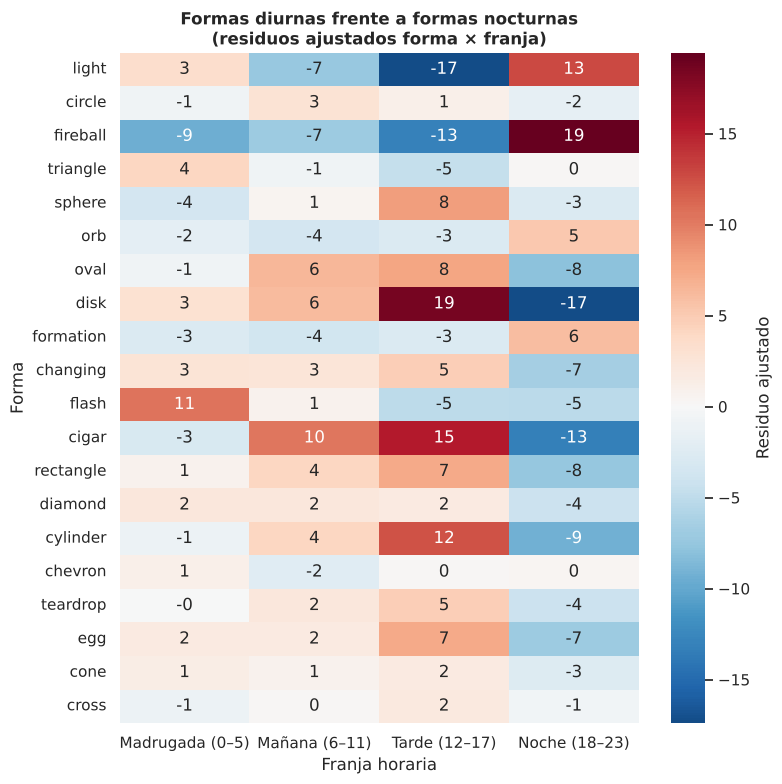

In [17]:
def franja(h):
    if h < 6:  return "Madrugada (0–5)"
    if h < 12: return "Mañana (6–11)"
    if h < 18: return "Tarde (12–17)"
    return "Noche (18–23)"
ORDEN_FRANJA = ["Madrugada (0–5)", "Mañana (6–11)", "Tarde (12–17)", "Noche (18–23)"]

base_ct = eda16[eda16["hora_conocida"] & eda16["forma_eda"].isin(conteo[conteo >= 30].index)].copy()
base_ct["franja"] = pd.Categorical(base_ct["hora"].astype(int).map(franja), ORDEN_FRANJA)
tabla_ct = pd.crosstab(base_ct["forma_eda"], base_ct["franja"])

chi2, p_chi, gl, esperadas = stats.chi2_contingency(tabla_ct)
n_ct = tabla_ct.values.sum()
v_cramer = np.sqrt(chi2 / (n_ct * (min(tabla_ct.shape) - 1)))
print(f"χ² = {chi2:,.1f}, gl = {gl}, p = {p_chi:.2e}, V de Cramér = {v_cramer:.3f} (n = {n_ct:,})")
print(f"Celdas con frecuencia esperada < 5: {(esperadas < 5).mean():.1%} (debe ser < 20 %)")

# Porcentaje por fila (perfil horario de cada forma)
display((pd.crosstab(base_ct["forma_eda"], base_ct["franja"], normalize="index") * 100)
        .sort_values("Noche (18–23)", ascending=False).round(1))

# Residuos estandarizados ajustados: |r| > 2 indica asociación local significativa
fila = tabla_ct.sum(axis=1).values[:, None] / n_ct
col = tabla_ct.sum(axis=0).values[None, :] / n_ct
residuos = (tabla_ct - esperadas) / np.sqrt(esperadas * (1 - fila) * (1 - col))
residuos = residuos.loc[tabla_ct.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(residuos, cmap="RdBu_r", center=0, annot=True, fmt=".0f", cbar_kws={"label": "Residuo ajustado"}, ax=ax)
ax.set(title="Formas diurnas frente a formas nocturnas\n(residuos ajustados forma × franja)",
       xlabel="Franja horaria", ylabel="Forma")
guardar_fig("fig05_residuos_forma_franja")

**Interpretación (Figura 5) — responde P2.** La forma declarada depende de la franja horaria (χ² = 2.287,5; gl = 57; p < 0,001; ninguna celda con frecuencia esperada < 5) con una asociación débil (V de Cramér = 0,136). Los residuos ajustados muestran un patrón nítido: *fireball* (80 % de sus reportes de noche; residuo +19), *light* (+13) y *formation* están sobrerrepresentadas de noche, mientras que *disk* (+19 en la tarde), *cigar* (+15) y *cylinder* (+12) lo están de día, cuando se puede distinguir un contorno; *flash* es la única forma asociada a la madrugada (+11). Para el negocio esto significa que **la forma reportada está condicionada por las condiciones de observación**: un analista nocturno recibirá sobre todo luces. Para la fase 3, justifica crear `franja_dia` y `grupo_forma` como variables del tablero.

### 2.4.3 Matriz de correlación de Spearman
Se usa Spearman (basada en rangos) porque las variables no son normales y las relaciones esperadas son monótonas, no necesariamente lineales.

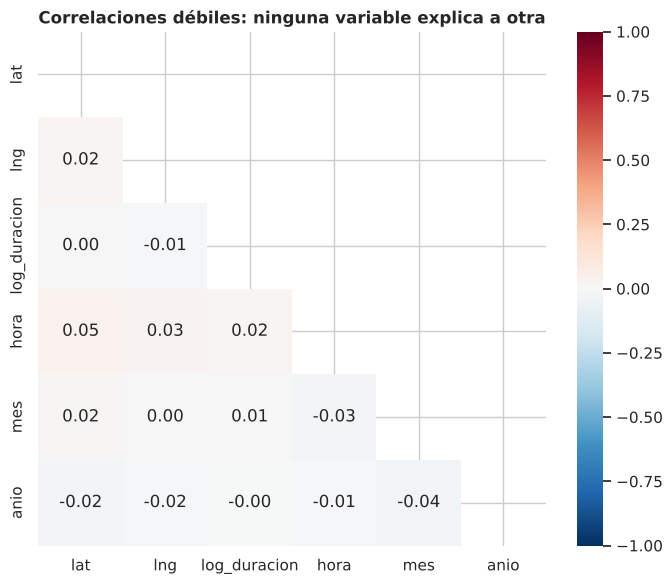

Pares con |ρ| ≥ 0,10:


Series([], dtype: float64)

In [18]:
vars_corr = ["lat", "lng", "log_duracion", "hora", "mes", "anio"]
base_corr = eda16[vars_corr].astype(float)
corr = base_corr.corr(method="spearman")

# Valores p por pares (eliminación por pares de faltantes)
pvals = pd.DataFrame(np.ones_like(corr), index=vars_corr, columns=vars_corr)
for a in vars_corr:
    for b in vars_corr:
        if a != b:
            par = base_corr[[a, b]].dropna()
            pvals.loc[a, b] = stats.spearmanr(par[a], par[b]).pvalue

mascara = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title="Correlaciones débiles: ninguna variable explica a otra")
guardar_fig("fig06_correlacion_spearman")
print("Pares con |ρ| ≥ 0,10:")
display(corr.where(~mascara).stack().loc[lambda s: s.abs() >= 0.10].round(3))

**Interpretación (Figura 6).** Todas las correlaciones son prácticamente nulas (|ρ| ≤ 0,046; la mayor es entre `lat` y `hora`). Aunque algunas son estadísticamente significativas por el tamaño de la muestra, ninguna tiene relevancia práctica. Que `log_duracion` casi no se relacione con `hora`, `mes` o `anio` indica que **la duración no sirve como predictor del volumen**, y que no hay multicolinealidad que impida usar a la vez variables de calendario en el Random Forest. Una limitación: la hora y el mes son **cíclicos** (23 h está cerca de 0 h) y Spearman no capta esa relación; por eso la hora se analiza con el mapa de calor siguiente y el modelo usa variables de calendario y no la hora en bruto.

### 2.4.4 Mapa de calor: hora × día de la semana

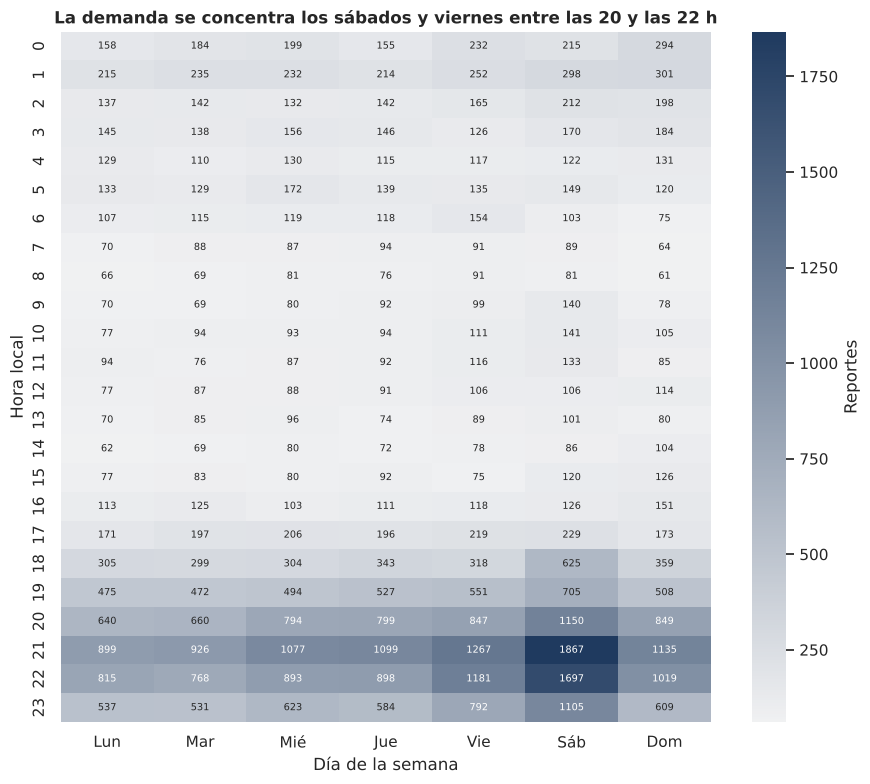

Celda máxima: Sáb a las 21:00 con 1,867 reportes
Razón celda máxima / celda mínima: 30.6


In [19]:
base_hd = eda16[eda16["hora_conocida"]]
mapa = pd.crosstab(base_hd["hora"].astype(int), base_hd["dia_semana"]).rename(columns=dict(enumerate(DIAS)))

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(mapa, cmap=sns.light_palette(AZUL, as_cmap=True), annot=True, fmt="d", annot_kws={"size": 7},
            cbar_kws={"label": "Reportes"}, ax=ax)
ax.set(title="La demanda se concentra los sábados y viernes entre las 20 y las 22 h",
       xlabel="Día de la semana", ylabel="Hora local")
guardar_fig("fig07_mapa_calor_hora_dia")

celda_max = mapa.stack().idxmax()
print(f"Celda máxima: {celda_max[1]} a las {celda_max[0]}:00 con {mapa.stack().max():,} reportes")
print(f"Razón celda máxima / celda mínima: {mapa.values.max() / max(mapa.values.min(), 1):.1f}")

**Interpretación (Figura 7) — responde P1.** Los reportes se concentran entre las 20:00 y las 23:00, sobre todo el sábado a las 21:00 (1.867 reportes, la celda máxima, 30,6 veces la mínima) y el sábado a las 22:00 (1.697), seguidos del viernes a las 21:00 y 22:00; los reportes casi desaparecen entre las 6:00 y las 16:00. La interacción entre hora y día (más actividad nocturna el fin de semana) es coherente con un fenómeno de **exposición**: más personas al aire libre y despiertas significa más observadores. Para el centro de recepción, esta matriz es directamente un **plan de turnos**; se replicará en Power BI como matriz con formato condicional.

### 2.4.5 Serie diaria y verificación de la hipótesis H1 (festivos con pirotecnia)

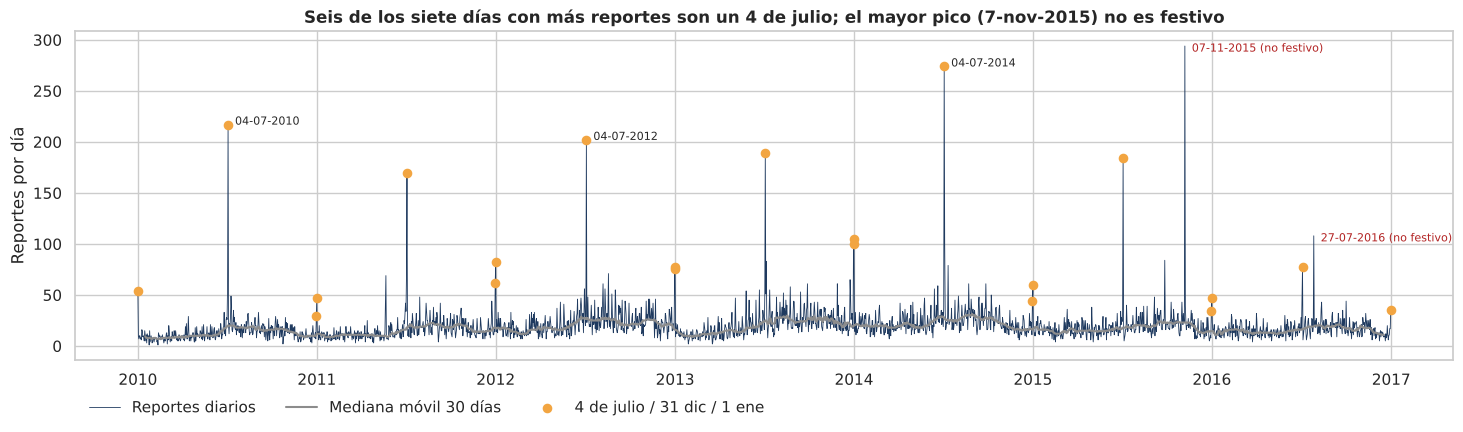

Los 10 días con más reportes:


,reportes,festivo_pirotecnia
2015-11-07,294,False
2014-07-04,274,True
2010-07-04,217,True
2012-07-04,202,True
2013-07-04,189,True
2015-07-04,184,True
2011-07-04,170,True
2016-07-27,108,False
2014-01-01,105,True
2014-07-05,102,False


Mediana diaria en festivos: 77 | resto: 17 | razón: 4.5x | Mann-Whitney (unilateral) p = 1.04e-14


In [20]:
diaria = (eda16.set_index("fecha_hora").resample("D").size()
          .reindex(pd.date_range("2010-01-01", "2016-12-31", freq="D"), fill_value=0))
es_festivo = (((diaria.index.month == 7) & (diaria.index.day == 4))
              | ((diaria.index.month == 12) & (diaria.index.day == 31))
              | ((diaria.index.month == 1) & (diaria.index.day == 1)))

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(diaria.index, diaria.values, color=AZUL, lw=0.6, label="Reportes diarios")
ax.plot(diaria.index, diaria.rolling(30, center=True).median(), color=GRIS, lw=1.5, label="Mediana móvil 30 días")
ax.scatter(diaria.index[es_festivo], diaria.values[es_festivo], color=AMBAR, s=35, zorder=3,
           label="4 de julio / 31 dic / 1 ene")
for f in diaria[es_festivo].nlargest(3).index:
    ax.annotate(f.strftime("%d-%m-%Y"), (f, diaria[f]), xytext=(5, 0), textcoords="offset points", fontsize=8)
# Picos que NO son festivos: eventos puntuales (ver interpretación)
for f in diaria[~es_festivo].nlargest(2).index:
    ax.annotate(f.strftime("%d-%m-%Y") + " (no festivo)", (f, diaria[f]), xytext=(5, -4),
                textcoords="offset points", fontsize=8, color="firebrick")
ax.set(title="Seis de los siete días con más reportes son un 4 de julio; el mayor pico (7-nov-2015) no es festivo",
       ylabel="Reportes por día")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3, frameon=False)
guardar_fig("fig08_serie_diaria_festivos")

print("Los 10 días con más reportes:")
top10 = diaria.nlargest(10).to_frame("reportes")
top10["festivo_pirotecnia"] = [f in diaria.index[es_festivo] for f in top10.index]
display(top10)

razon = diaria[es_festivo].median() / diaria[~es_festivo].median()
u, p_mw = stats.mannwhitneyu(diaria[es_festivo], diaria[~es_festivo], alternative="greater")
print(f"Mediana diaria en festivos: {diaria[es_festivo].median():.0f} | resto: {diaria[~es_festivo].median():.0f} "
      f"| razón: {razon:.1f}x | Mann-Whitney (unilateral) p = {p_mw:.2e}")

In [21]:
# Segunda parte de H1: ¿aumenta la proporción de 'fireball' y 'light' en esos días?
md = eda16["fecha_hora"].dt.strftime("%m-%d")
eda16["festivo_pirotecnia"] = md.isin(["07-04", "12-31", "01-01"])
base_h1 = eda16.dropna(subset=["forma_eda"])
base_h1 = base_h1.assign(luz_fuego=base_h1["forma_eda"].isin(["fireball", "light"]))
tabla_h1 = pd.crosstab(base_h1["festivo_pirotecnia"], base_h1["luz_fuego"])
chi2_h1, p_h1, _, _ = stats.chi2_contingency(tabla_h1)
prop = base_h1.groupby("festivo_pirotecnia")["luz_fuego"].mean() * 100
odds = (tabla_h1.loc[True, True] * tabla_h1.loc[False, False]) / (tabla_h1.loc[True, False] * tabla_h1.loc[False, True])
print(f"% fireball+light — días normales: {prop[False]:.1f} % | festivos pirotecnia: {prop[True]:.1f} %")
print(f"χ² = {chi2_h1:,.1f}, p = {p_h1:.2e}, razón de momios (OR) = {odds:.2f}")

perfil = (pd.crosstab(base_h1["forma_eda"], base_h1["festivo_pirotecnia"], normalize="columns") * 100)
perfil.columns = ["Días normales (%)", "Festivos pirotecnia (%)"]
display(perfil.assign(diferencia_pp=lambda t: t.iloc[:, 1] - t.iloc[:, 0])
        .sort_values("diferencia_pp", ascending=False).head(6).round(1))

% fireball+light — días normales: 34.8 % | festivos pirotecnia: 39.8 %
χ² = 20.0, p = 7.64e-06, razón de momios (OR) = 1.24


,Días normales (%),Festivos pirotecnia (%),diferencia_pp
forma_eda,,,
fireball,12.000,20.100,8.100
sphere,6.200,9.200,3.000
circle,12.400,15.400,3.000
orb,6.000,8.600,2.600
egg,0.800,1.000,0.300
oval,4.900,4.900,0.000


In [22]:
# Control de estacionalidad: festivos frente a los DEMÁS días del MISMO mes
ctrl = []
for mes_ in (1, 7, 12):
    en_mes = diaria.index.month == mes_
    ctrl.append({'mes': mes_, 'mediana_festivos': diaria[en_mes & es_festivo].median(),
                 'mediana_otros_dias_del_mes': diaria[en_mes & ~es_festivo].median()})
ctrl = pd.DataFrame(ctrl).assign(razon=lambda t: t['mediana_festivos'] / t['mediana_otros_dias_del_mes'])
display(ctrl.round(1))

,mes,mediana_festivos,mediana_otros_dias_del_mes,razon
0,1,60.000,13.000,4.600
1,7,189.000,21.000,9.000
2,12,44.000,14.000,3.100


**Interpretación (Figura 8) — verifica H1.** De los diez días con más reportes en siete años, siete son festivos con pirotecnia (los seis 4 de julio de 2010–2015 y el 1 de enero de 2014), y la mediana diaria en esos días es 4,5 veces la de un día normal (77 frente a 17; Mann-Whitney unilateral, p < 0,001). El efecto del 4 de julio es mucho más fuerte que el de Año Nuevo (picos de 170–274 frente a 30–105 reportes). La proporción de *fireball* + *light* sube de 34,8 % a 39,8 % (χ² = 20,0; p < 0,001; OR = 1,24), pero **el aumento se debe solo a *fireball*** (de 12,0 % a 20,1 %), mientras que *light* baja de 22,8 % a 19,7 %. **H1 se confirma parcialmente:** el pico de volumen es claro y la forma asociada a la pirotecnia es *fireball*, no *light*.

*Cautela metodológica:* la razón de 4,5 compara los festivos con **todos** los demás días del año y julio y enero ya son meses de volumen alto. Como control, la celda anterior compara cada festivo con los demás días del **mismo mes**: la razón de medianas es 4,6 en enero, 9,0 en julio y 3,1 en diciembre, es decir, el efecto no es un artefacto de la estacionalidad (en julio es incluso mayor). Aun así, los 21 festivos (7 años × 3 fechas) son pocos y los días consecutivos no son independientes, de modo que el valor p debe leerse como indicativo.

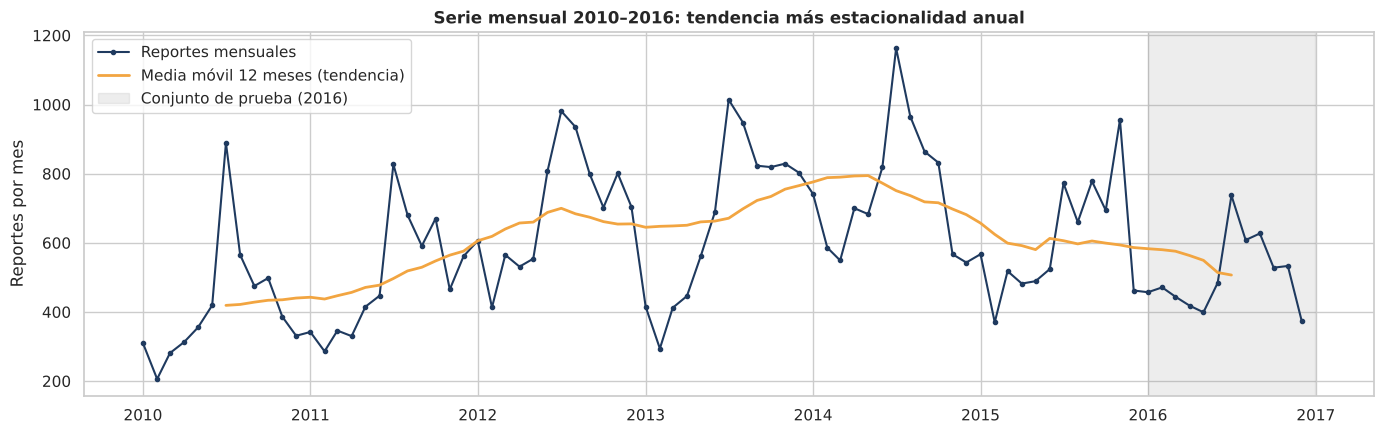

Meses en la serie: 84 (entrenamiento 2010–2015: 72, prueba 2016: 12)
Coeficiente de variación mensual: 0.35
Autocorrelación en el rezago 12: 0.628


In [23]:
mensual_serie = eda16.set_index("fecha_hora").resample("MS").size()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(mensual_serie.index, mensual_serie.values, color=AZUL, marker="o", ms=3, label="Reportes mensuales")
ax.plot(mensual_serie.index, mensual_serie.rolling(12, center=True).mean(), color=AMBAR, lw=2, label="Media móvil 12 meses (tendencia)")
ax.axvspan(pd.Timestamp("2016-01-01"), pd.Timestamp("2016-12-31"), color=GRIS, alpha=0.15, label="Conjunto de prueba (2016)")
ax.set(title="Serie mensual 2010–2016: tendencia más estacionalidad anual", ylabel="Reportes por mes")
ax.legend(loc="upper left")
guardar_fig("fig09_serie_mensual")

print(f"Meses en la serie: {len(mensual_serie)} (entrenamiento 2010–2015: 72, prueba 2016: 12)")
print(f"Coeficiente de variación mensual: {mensual_serie.std() / mensual_serie.mean():.2f}")
print("Autocorrelación en el rezago 12:", round(mensual_serie.autocorr(12), 3))

**Interpretación (Figura 9) — prepara P3.** La serie mensual combina una **tendencia** creciente hasta 2014 y decreciente después (la media mensual pasa de 419 en 2010 a 751 en 2014 y a 507 en 2016) con un **patrón anual repetido** (pico en julio) y una autocorrelación en el rezago 12 de 0,63, señal de estacionalidad de período 12. El coeficiente de variación mensual es 0,35. Con 84 meses hay seis ciclos completos para entrenar (2010–2015) y uno para evaluar (2016), lo mínimo razonable para un modelo estacional. Por eso la fase 4 compara un **ingenuo estacional** (repite el mismo mes del año anterior), un modelo que modela tendencia y estacionalidad (**SARIMA u Holt-Winters**) y un **Random Forest con variables de calendario**; la prueba ADF y los gráficos ACF/PACF confirmarán formalmente el orden de diferenciación. **Riesgo identificado:** como 2016 continúa la caída iniciada en 2015, el ingenuo estacional (que copia 2015) partirá de un nivel algo alto y un modelo con tendencia lineal puede sobreestimar aún más; por eso no se debe extrapolar una pendiente fija: se comparan configuraciones con tendencia amortiguada, con diferenciación y sin tendencia, y se elige con criterios de información (AICc/AIC).

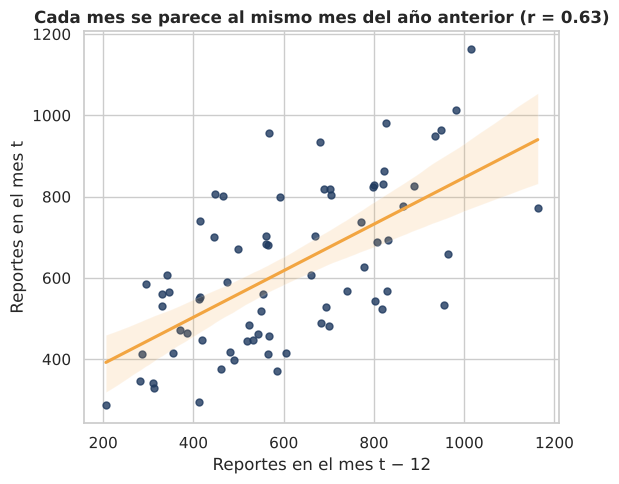

Pares (t, t−12): 72 | r de Pearson = 0.628 | rho de Spearman = 0.608


In [24]:
# Diagrama de dispersión: volumen del mes t frente al mismo mes del año anterior (t − 12)
par = pd.DataFrame({'mes_t_menos_12': mensual_serie.shift(12), 'mes_t': mensual_serie}).dropna()
r_p = par['mes_t_menos_12'].corr(par['mes_t'])
fig, ax = plt.subplots(figsize=(6, 5))
sns.regplot(data=par, x='mes_t_menos_12', y='mes_t', color=AZUL, line_kws={'color': AMBAR}, scatter_kws={'s': 25}, ax=ax)
ax.set(title=f'Cada mes se parece al mismo mes del año anterior (r = {r_p:.2f})',
       xlabel='Reportes en el mes t − 12', ylabel='Reportes en el mes t')
guardar_fig('fig09b_dispersion_rezago12')
print(f'Pares (t, t−12): {len(par)} | r de Pearson = {r_p:.3f} | rho de Spearman = {stats.spearmanr(par.mes_t_menos_12, par.mes_t)[0]:.3f}')

**Interpretación (diagrama de dispersión, Figura 9b).** La nube de 72 pares (mes *t*, mes *t* − 12) asciende con una correlación de 0,63: un mes con muchos reportes tiende a ir seguido, un año después, de otro mes alto. Es la misma estacionalidad de período 12 que muestra la autocorrelación. La dispersión alrededor de la recta es amplia porque la tendencia no es monótona (2012–2014 sube y 2015–2016 baja): el mismo mes cambia de nivel de un año a otro. Por eso repetir el año anterior (ingenuo estacional) es una referencia útil pero imperfecta.

## 2.5 Síntesis del EDA: de los hallazgos a las decisiones

| Hallazgo | Evidencia | Decisión en la fase 3 (ETL) | Decisión en las fases 4–5 (modelo) |
|---|---|---|---|
| Duración muy asimétrica, redondeada y con extremos | Media 542 s frente a mediana 180 s; asimetría 62,3; 72 % múltiplos de 60; Fig. 1 | Umbral de 24 h, `log_duracion`, `rango_duracion`, imputación con mediana por forma + marca | La duración no entra al modelo de volumen |
| La duración varía por forma (efecto pequeño) | Kruskal-Wallis, η²_H = 0,018; Fig. 4 | Imputación por forma | — |
| 24 formas, varias raras; 15 % sin forma | Tabla de frecuencias; Fig. 2 | `grupo_forma` (6 grupos), "desconocida" | — |
| Forma asociada a la franja (débil) | χ², V = 0,136; Fig. 5 | `franja_dia` | Segmentación en el tablero |
| 1.624 registros sin hora | Diagnóstico 2.2 | `hora_conocida`; hora = nulo | No afecta conteos diarios ni mensuales |
| Picos en festivos con pirotecnia (sobre todo 4 de julio y *fireball*) | Fig. 8; Mann-Whitney y χ² | `festivo_pirotecnia` | Variable de calendario en el Random Forest; atípicos en la serie semanal |
| Tendencia no monótona + estacionalidad 12 | Fig. 3 y 9; ACF(12) = 0,63 | Agregación mensual y semanal | SARIMA y Holt-Winters (configuración elegida por AICc) frente a ingenuo estacional |
| Picos por eventos no festivos (7-nov-2015) | Fig. 8 | Conservarlos (son reportes reales) | Limitación: eventos impredecibles |
| 2017 incompleto | 197 registros | Excluir del modelo y de los análisis anuales | Serie 2010–2016 |
| 90 % de los reportes de EE. UU. | Tabla de países | Imputar país desde coordenadas | Limitación de generalización |

---
# FASE 3. Preparación de los datos: proceso ETL

**Principio de trazabilidad:** `df_raw` (el archivo original) no se modifica. Todo el ETL trabaja sobre una copia (`df`) y cada etapa queda registrada con `log_step()`, que guarda las filas y columnas antes y después y el número de registros afectados. La tabla completa del registro se muestra al final del cuaderno y se exporta como `registro_etl.csv`.

In [25]:
# --- Registro de cambios del ETL ---
registro_etl = []

def log_step(etapa, df_antes, df_despues, descripcion, afectados=None):
    """Registra una etapa del ETL: dimensiones antes/después y registros afectados."""
    registro_etl.append({
        "paso": len(registro_etl) + 1,
        "etapa": etapa,
        "filas_antes": df_antes.shape[0], "columnas_antes": df_antes.shape[1],
        "filas_despues": df_despues.shape[0], "columnas_despues": df_despues.shape[1],
        "delta_filas": df_despues.shape[0] - df_antes.shape[0],
        "delta_columnas": df_despues.shape[1] - df_antes.shape[1],
        "registros_afectados": afectados,
        "descripcion": descripcion,
    })
    print(f"[{len(registro_etl):02d}] {etapa}: {df_antes.shape} -> {df_despues.shape} | afectados: {afectados}")

# Etapa 0: extracción (de un DataFrame vacío al archivo original)
log_step("Extracción", pd.DataFrame(), df_raw, "Lectura de data/raw/uap-atlas-reports-2010-2100.csv (UTF-8)",
         afectados=len(df_raw))

[01] Extracción: (0, 0) -> (50000, 11) | afectados: 50000


## 3.1 Diagnóstico de calidad antes de intervenir
Se consolida en una sola tabla lo detectado en la fase 2: nulos, categorías que funcionan como nulos, duplicados, atípicos, tipos de dato incorrectos, categorías inconsistentes y registros fuera del periodo útil.

In [26]:
d_raw = df_raw["durationSec"]
claves_dup = ["datetime", "lat", "lng", "shape"]
q1_log, q3_log = np.log10(d_raw).quantile([0.25, 0.75])

diagnostico = pd.DataFrame([
    ("Nulos", "durationSec", d_raw.isna().sum()),
    ("Nulos", "country", df_raw["country"].isna().sum()),
    ("Nulos", "shape", df_raw["shape"].isna().sum()),
    ("Categoría que funciona como nulo", "shape = unknown / other", df_raw["shape"].isin(["unknown", "other"]).sum()),
    ("Duplicados", "misma fecha-hora, lat, lng y forma", df_raw.duplicated(claves_dup).sum()),
    ("Atípicos extremos", "durationSec > 24 h", (d_raw > 86_400).sum()),
    ("Atípicos (Tukey, escala log)", "durationSec", ((np.log10(d_raw) < q1_log - 1.5 * (q3_log - q1_log)) |
                                                     (np.log10(d_raw) > q3_log + 1.5 * (q3_log - q1_log))).sum()),
    ("Tipo de dato incorrecto", "datetime leído como texto", len(df_raw)),
    ("Información incompleta", "datetime sin hora", (~df_raw["datetime"].str.contains("T")).sum()),
    ("Categoría inconsistente", "shape con mayúsculas o espacios",
     (df_raw["shape"].dropna() != df_raw["shape"].dropna().str.strip().str.lower()).sum()),
    ("Categoría inconsistente", "country con formato distinto a ISO-3",
     (~df_raw["country"].dropna().str.fullmatch(r"[A-Z]{3}")).sum()),
    ("Columna sin variabilidad", "source, locationPrecision (constantes); status (99,97 % open)", 3),
    ("Fuera del periodo útil", "año 2017 incompleto", (fecha.dt.year == 2017).sum()),
], columns=["problema", "variable / regla", "registros"])
diagnostico["pct"] = (diagnostico["registros"] / len(df_raw) * 100).round(2)
diagnostico

,problema,variable / regla,registros,pct
0,Nulos,durationSec,7711,15.420
1,Nulos,country,1443,2.890
2,Nulos,shape,993,1.990
3,Categoría que funciona como nulo,shape = unknown / other,6416,12.830
4,Duplicados,"misma fecha-hora, lat, lng y forma",439,0.880
5,Atípicos extremos,durationSec > 24 h,11,0.020
6,"Atípicos (Tukey, escala log)",durationSec,12,0.020
7,Tipo de dato incorrecto,datetime leído como texto,50000,100.000
8,Información incompleta,datetime sin hora,1624,3.250
9,Categoría inconsistente,shape con mayúsculas o espacios,0,0.000


**Lectura del diagnóstico.** No hay problemas de formato en las categorías (formas en minúscula y países en ISO-3), de modo que la limpieza se concentra en **faltantes**, **atípicos de duración**, **duplicados**, el **tipo de dato de la fecha** y las **columnas sin variabilidad**. Cada tratamiento se presenta a continuación con su justificación y el número de registros afectados.

## 3.2 Tratamientos de limpieza

### a) Conversión de `datetime` y marca `hora_conocida`
**Justificación:** el análisis temporal (P1) y las series del modelo (P3) requieren un tipo fecha. Como el 3,2 % de los registros solo trae la fecha, al convertirlos quedarían a las 00:00 y crearían un pico artificial a medianoche. La marca `hora_conocida` permite excluirlos del análisis por hora **sin eliminarlos** de los conteos diarios, semanales y mensuales, donde la fecha basta.

In [27]:
df = df_raw.copy()
antes = df.copy()
df["hora_conocida"] = df["datetime"].str.contains("T")
df["fecha_hora"] = pd.to_datetime(df["datetime"], format="ISO8601")
df = df.drop(columns="datetime")
log_step("a) Conversión de datetime + hora_conocida", antes, df,
         "datetime (texto) -> fecha_hora (datetime64); marca booleana de hora conocida",
         afectados=int((~df["hora_conocida"]).sum()))
print(df["fecha_hora"].dtype, "| registros sin hora:", (~df["hora_conocida"]).sum())

[02] a) Conversión de datetime + hora_conocida: (50000, 11) -> (50000, 12) | afectados: 1624
datetime64[ns] | registros sin hora: 1624


### b) Revisión de duplicados
Hay 439 registros que repiten fecha-hora, coordenadas y forma con otro registro. Antes de eliminarlos hay que saber **qué son**: ¿reenvíos de la misma persona o testigos distintos del mismo evento? La evidencia se obtiene del número de reporte de NUFORC (consecutivo según el orden de llegada) y de las fechas en que se concentran.

In [28]:
dup_mask = df.duplicated(["fecha_hora", "lat", "lng", "shape"], keep="first")
grupo_dup = df[df.duplicated(["fecha_hora", "lat", "lng", "shape"], keep=False)].copy()
grupo_dup["num_reporte"] = grupo_dup["sourceUrl"].str.extract(r"id=(\d+)", expand=False).astype(int)
saltos = (grupo_dup.sort_values("num_reporte")
          .groupby(["fecha_hora", "lat", "lng", "shape"], dropna=False)["num_reporte"].diff().dropna())

print(f"Registros marcados como posibles duplicados: {dup_mask.sum()}")
print(f"Distancia entre números de reporte dentro de un grupo: mediana = {saltos.median():.0f}, "
      f"consecutivos (distancia 1) = {(saltos == 1).mean():.1%}")
print("\nFechas (mes-día) donde más se concentran:")
display(grupo_dup["fecha_hora"].dt.strftime("%m-%d").value_counts().head(5).to_frame("registros"))

# Sensibilidad: ¿cambia la serie mensual si se eliminan?
m_con = df[df["fecha_hora"].dt.year <= 2016].set_index("fecha_hora").resample("MS").size()
m_sin = df[(~dup_mask) & (df["fecha_hora"].dt.year <= 2016)].set_index("fecha_hora").resample("MS").size()
print(f"\nDiferencia máxima en la serie mensual si se eliminaran: {((m_con - m_sin) / m_con).max():.2%}")

antes = df.copy()
df["posible_duplicado"] = dup_mask
log_step("b) Marca de posibles duplicados (se conservan)", antes, df,
         "Se conservan: son testigos distintos del mismo evento; cada reporte es carga de trabajo",
         afectados=int(dup_mask.sum()))

Registros marcados como posibles duplicados: 439
Distancia entre números de reporte dentro de un grupo: mediana = 9, consecutivos (distancia 1) = 21.6%

Fechas (mes-día) donde más se concentran:


,registros
fecha_hora,
07-04,47
07-03,14
11-07,13
10-14,10
04-27,9



Diferencia máxima en la serie mensual si se eliminaran: 1.93%
[03] b) Marca de posibles duplicados (se conservan): (50000, 12) -> (50000, 13) | afectados: 439


**Decisión: conservar y marcar.** Solo una minoría de los pares son reportes consecutivos; en la mayoría hay otros reportes de por medio, lo que indica envíos independientes. Además, se concentran en eventos masivos (4 de julio y 7 de noviembre, el día del misil Trident). Para un centro de recepción **cada reporte es carga de trabajo**, aunque describa el mismo evento, y la unidad de observación es el reporte, no el evento. Eliminarlos subestimaría la demanda justamente en los días pico. La sensibilidad muestra que la serie mensual cambia muy poco. Se conserva la marca `posible_duplicado` para que el tablero permita filtrarlos.

### c) Unificación de formas no informativas y agrupación
**Justificación:** los nulos, *unknown* y *other* significan lo mismo para el negocio (la persona no pudo describir la forma). Mantenerlos separados divide artificialmente una categoría que suma el 14,8 % del total. Se unifican en `desconocida`. En el mismo paso se crea `grupo_forma` (documentado en la sección 3.3), porque la imputación de la duración la usa como respaldo para las formas con muy pocos casos.

In [29]:
GRUPOS_FORMA = {
    "luces": ["light", "flash", "fireball", "star", "orb"],
    "redondas": ["circle", "sphere", "disk", "oval", "egg"],
    "angulares": ["triangle", "chevron", "diamond", "rectangle", "cube", "cross", "cone"],
    "alargadas": ["cigar", "cylinder", "teardrop"],
    "formación/cambiante": ["formation", "changing"],
    "desconocida": ["desconocida"],
}
FORMA_A_GRUPO = {f: g for g, formas in GRUPOS_FORMA.items() for f in formas}

antes = df.copy()
afectados_c = int((df["shape"].isna() | df["shape"].isin(["unknown", "other"])).sum())
df["forma_reportada"] = df["shape"].fillna("(nulo)")          # trazabilidad: valor original
df["forma"] = df["shape"].replace({"unknown": np.nan, "other": np.nan}).fillna("desconocida")
df["grupo_forma"] = df["forma"].map(FORMA_A_GRUPO)
df = df.drop(columns="shape")
assert df["grupo_forma"].notna().all(), "Hay formas sin grupo asignado"
log_step("c) Unificación de forma desconocida + grupo_forma", antes, df,
         "NaN, 'unknown' y 'other' -> 'desconocida'; 24 formas -> 6 grupos", afectados=afectados_c)
display(df["grupo_forma"].value_counts().to_frame("reportes"))

[04] c) Unificación de forma desconocida + grupo_forma: (50000, 13) -> (50000, 15) | afectados: 7409


,reportes
grupo_forma,
luces,18482
redondas,12383
desconocida,7409
angulares,6843
formación/cambiante,2869
alargadas,2014


### d) Imputación de `country` desde las coordenadas
**Justificación:** `lat` y `lng` están completos, así que el país no es un dato perdido sino un dato **deducible**. Imputar con la moda (USA) sería un error para los reportes de otros continentes. Se usan dos métodos, y ambos se **validan** sobre los registros cuyo país sí se conoce:
1. **Principal: `reverse_geocoder`**, sin conexión. Devuelve el código ISO-2 de la ciudad más cercana. La conversión a ISO-3 se aprende de los propios datos, cruzando ISO-2 con el país conocido.
2. **Respaldo: vecino más cercano** con distancia de Haversine (`BallTree`) entre los reportes de país conocido. Se usa si la librería no está instalada o si el código ISO-2 no aparece en los datos.

In [30]:
from sklearn.neighbors import BallTree

conocido = df["country"].notna()
coords_conocidas = np.radians(df.loc[conocido, ["lat", "lng"]].to_numpy())
paises_conocidos = df.loc[conocido, "country"].to_numpy()

def pais_vecino_mas_cercano(lat, lng, coords_ref=coords_conocidas, etiquetas=paises_conocidos):
    """Asigna el país del reporte conocido más cercano (distancia de Haversine)."""
    arbol = BallTree(coords_ref, metric="haversine")
    _, idx = arbol.query(np.radians(np.column_stack([lat, lng])), k=1)
    return etiquetas[idx[:, 0]]

# Validación del respaldo: 20 % de los conocidos se ocultan y se predicen con el 80 % restante
rng = np.random.default_rng(RANDOM_STATE)
val = rng.random(conocido.sum()) < 0.20
pred_val = pais_vecino_mas_cercano(df.loc[conocido, "lat"].to_numpy()[val], df.loc[conocido, "lng"].to_numpy()[val],
                                   coords_conocidas[~val], paises_conocidos[~val])
exactitud_knn = (pred_val == paises_conocidos[val]).mean()
print(f"Exactitud del vecino más cercano en validación (n = {val.sum():,}): {exactitud_knn:.2%}")

# Método principal: reverse_geocoder (si está instalado)
metodo_pais, exactitud_rg = "vecino más cercano", np.nan
try:
    import reverse_geocoder as rg
    coords_unicas = df[["lat", "lng"]].drop_duplicates()
    # mode=1 (un solo proceso): evita bloqueos de multiprocessing en Jupyter/Windows
    res_rg = rg.search(list(coords_unicas.itertuples(index=False, name=None)), mode=1)
    coords_unicas = coords_unicas.assign(iso2=[r["cc"] for r in res_rg])
    df_rg = df.merge(coords_unicas, on=["lat", "lng"], how="left")
    # ISO-2 -> ISO-3 aprendido de los registros con país conocido (moda de cada ISO-2)
    mapa_iso = (df_rg[df_rg["country"].notna()].groupby("iso2")["country"]
                .agg(lambda s: s.value_counts().index[0]).to_dict())
    pred_rg = df_rg["iso2"].map(mapa_iso)
    exactitud_rg = (pred_rg[conocido.values] == df.loc[conocido, "country"].values).mean()
    print(f"Exactitud de reverse_geocoder sobre los {conocido.sum():,} países conocidos: {exactitud_rg:.2%}")
    metodo_pais = "reverse_geocoder + respaldo vecino más cercano"
except ImportError:
    pred_rg = pd.Series(np.nan, index=df.index, dtype="object")
    print("reverse_geocoder no está instalado: se usa solo el vecino más cercano (pip install reverse_geocoder).")

antes = df.copy()
faltante = df["country"].isna()
imputado = pd.Series(pred_rg.values, index=df.index, dtype="object").where(faltante)
sin_rg = faltante & imputado.isna()                            # sin librería o ISO-2 no visto en los datos
if sin_rg.any():
    imputado.loc[sin_rg] = pais_vecino_mas_cercano(df.loc[sin_rg, "lat"].to_numpy(), df.loc[sin_rg, "lng"].to_numpy())
df["pais"] = df["country"].fillna(imputado)
df["pais_imputado"] = faltante
df = df.drop(columns="country")
log_step("d) Imputación de país desde lat/lng", antes, df,
         f"Método: {metodo_pais}; 'country' -> 'pais' + marca pais_imputado", afectados=int(faltante.sum()))
print("Nulos restantes en pais:", df["pais"].isna().sum())
display(df.loc[df["pais_imputado"], "pais"].value_counts().head(8).to_frame("imputados"))

Exactitud del vecino más cercano en validación (n = 9,688): 99.76%
Loading formatted geocoded file...


Exactitud de reverse_geocoder sobre los 48,557 países conocidos: 99.77%
[05] d) Imputación de país desde lat/lng: (50000, 15) -> (50000, 16) | afectados: 1443
Nulos restantes en pais: 0


,imputados
pais,
USA,1158
CAN,77
ZAF,20
GBR,17
ESP,15
PHL,14
ITA,11
IND,10


### e) Duración: atípicos extremos e imputación
**Atípicos.** Se fija un umbral de **24 horas** (86.400 s), con un criterio de negocio: un avistamiento continuo de más de un día no es plausible como observación única. Lo más probable es que describa un fenómeno recurrente o que se haya escrito mal la unidad. Además, ese umbral está a 3,35 desviaciones estándar de la media en escala logarítmica, más allá de cualquier límite estadístico habitual. Esos valores se tratan como **no válidos**: se pasan a faltante y se marcan con `duracion_atipica`. No se recortan a 24 h, porque eso inventaría una duración.

**Imputación.** No se usa la media: es tres veces la mediana por la asimetría (fase 2). Se imputa con la **mediana de la forma**, porque el análisis de Kruskal-Wallis mostró que la duración cambia según la forma. Las formas con menos de 30 duraciones válidas usan la mediana de su `grupo_forma`. Se conservan dos columnas:
- `duracion_seg_reportada`: solo los valores válidos, con faltantes. Se usa en el tablero y en las estadísticas, para no distorsionar la distribución.
- `duracion_seg`: completa (imputada), con la marca `duracion_imputada`. Sirve para análisis que requieran todos los registros.

In [31]:
UMBRAL_SEG = 86_400
antes = df.copy()
df["duracion_atipica"] = df["durationSec"] > UMBRAL_SEG
print(f"Valores > 24 h: {df['duracion_atipica'].sum()} | z en escala log del umbral: "
      f"{(np.log10(UMBRAL_SEG) - np.log10(d_raw).mean()) / np.log10(d_raw).std():.2f}")
df["duracion_seg_reportada"] = df["durationSec"].mask(df["duracion_atipica"])
df = df.drop(columns="durationSec")
log_step("e1) Duraciones > 24 h -> no válidas", antes, df,
         "Valores > 86.400 s pasan a faltante; marca duracion_atipica", afectados=int(df["duracion_atipica"].sum()))

antes = df.copy()
n_validos = df.groupby("forma")["duracion_seg_reportada"].transform("count")
med_forma = df.groupby("forma")["duracion_seg_reportada"].transform("median")
med_grupo = df.groupby("grupo_forma")["duracion_seg_reportada"].transform("median")
mediana_imputacion = med_forma.where(n_validos >= 30, med_grupo)
df["duracion_imputada"] = df["duracion_seg_reportada"].isna()
df["duracion_seg"] = df["duracion_seg_reportada"].fillna(mediana_imputacion)
log_step("e2) Imputación de duración (mediana por forma)", antes, df,
         "Mediana por forma (grupo si < 30 casos válidos); marca duracion_imputada",
         afectados=int(df["duracion_imputada"].sum()))

tabla_imp = (df.groupby("forma").agg(n=("forma", "size"), imputados=("duracion_imputada", "sum"),
                                     mediana_usada_s=("duracion_seg", lambda s: mediana_imputacion[s.index].iloc[0]))
             .sort_values("imputados", ascending=False))
display(tabla_imp.head(8))
print("Comparación de la distribución (sin y con imputación):")
display(pd.DataFrame({"reportada": df["duracion_seg_reportada"].describe(),
                      "imputada": df["duracion_seg"].describe()}).T)

Valores > 24 h: 11 | z en escala log del umbral: 3.35
[06] e1) Duraciones > 24 h -> no válidas: (50000, 16) -> (50000, 17) | afectados: 11
[07] e2) Imputación de duración (mediana por forma): (50000, 17) -> (50000, 19) | afectados: 7722


,n,imputados,mediana_usada_s
forma,,,
desconocida,7409,1574,180.000
light,9647,1382,180.000
circle,5325,914,180.000
triangle,4370,651,120.000
fireball,5267,526,180.000
disk,1946,409,180.000
sphere,2694,324,180.000
oval,2090,320,180.000


Comparación de la distribución (sin y con imputación):


,count,mean,std,min,25%,50%,75%,max
reportada,"42,278.000",502.977,965.774,1.000,38.250,180.000,600.000,"36,000.000"
imputada,"50,000.000",452.356,896.080,1.000,60.000,180.000,300.000,"36,000.000"


**Efecto de la imputación.** Se imputaron 7.722 duraciones (7.711 faltantes y 11 atípicos). La mediana global no cambia (180 s), pero el rango intercuartílico se reduce de 562 s a 240 s y la media baja de 503 s a 452 s: es el costo conocido de imputar con medianas, que concentra valores en el centro. **Por eso, las estadísticas y los gráficos de duración del tablero usan `duracion_seg_reportada`**, y `duracion_seg` solo se usa cuando se necesitan todos los registros. La forma `desconocida` tiene una tasa de faltantes en duración más alta que el promedio (21 % frente a 15 %): quien no puede describir la forma tampoco suele estimar la duración.

### f) Eliminación de columnas sin valor analítico y exclusión de 2017
- `source` y `locationPrecision`: constantes, con varianza cero. No discriminan nada.
- `status`: el 99,97 % es *open*. Como variable objetivo de clasificación tendría 15 casos positivos entre 50.000, y un modelo trivial que siempre diga "open" acertaría el 99,97 % sin aprender nada. Además, *explained* no significa "falso": solo indica que NUFORC revisó el caso.
- `sourceUrl`: identificador redundante con `id`, que sí se conserva como llave de la tabla de hechos.
- **2017**: solo 18 días (197 registros). Incluirlo distorsionaría el total anual en el tablero (aparentaría una caída del 97 %) y el modelo, que necesita meses completos.

In [32]:
antes = df.copy()
df = df.drop(columns=["source", "locationPrecision", "status", "sourceUrl"])
log_step("f1) Eliminación de columnas sin valor analítico", antes, df,
         "source, locationPrecision (constantes), status (99,97 % open), sourceUrl (redundante con id)", afectados=0)

antes = df.copy()
n_2017 = int((df["fecha_hora"].dt.year == 2017).sum())
df = df[df["fecha_hora"].dt.year <= 2016].reset_index(drop=True)
log_step("f2) Exclusión de 2017 (año incompleto)", antes, df, "Se conservan 2010-01-01 a 2016-12-31", afectados=n_2017)

[08] f1) Eliminación de columnas sin valor analítico: (50000, 19) -> (50000, 15) | afectados: 0
[09] f2) Exclusión de 2017 (año incompleto): (50000, 15) -> (49803, 15) | afectados: 197


## 3.3 Ingeniería de variables

| Variable | Justificación |
|---|---|
| `fecha`, `anio`, `mes`, `dia_semana_num`, `dia_semana`, `hora` | Desagregan la fecha para responder P1 y para relacionar con la tabla calendario de Power BI. La hora queda vacía si no se conoce. |
| `fin_de_semana` | La fase 2 mostró 34,6 % de reportes en fin de semana frente a 28,6 % esperado. |
| `franja_dia` | La forma depende de la franja (χ², V = 0,136). Es una variable más legible que la hora para el tablero y el filtrado. |
| `festivo_pirotecnia` | El 4 de julio y Año Nuevo multiplican por 4,5 el volumen diario (H1). Sirve como regresor del modelo y como filtro del tablero. |
| `log_duracion` | Corrige la asimetría (de 62,3 a −0,43). Se usa en escala log10 para que sea interpretable (2 = 100 s). |
| `rango_duracion` | Las duraciones son estimaciones redondeadas, así que los rangos son más honestos que el valor exacto. Sirve para el histograma por rangos del tablero. |
| `grupo_forma` | 24 formas con frecuencias desiguales (*cube* = 2) se agrupan en 6 grupos con suficiente tamaño. |
| Agregaciones mensual y semanal | Las requiere el modelo de series de tiempo (P3). |

In [33]:
antes = df.copy()
DIAS_LARGO = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

df["fecha"] = df["fecha_hora"].dt.normalize()
df["anio"] = df["fecha_hora"].dt.year
df["mes"] = df["fecha_hora"].dt.month
df["dia_semana_num"] = df["fecha_hora"].dt.dayofweek + 1               # 1 = lunes ... 7 = domingo
df["dia_semana"] = df["dia_semana_num"].map(dict(enumerate(DIAS_LARGO, start=1)))
df["hora"] = df["fecha_hora"].dt.hour.where(df["hora_conocida"]).astype("Int64")
df["fin_de_semana"] = df["dia_semana_num"] >= 6

FRANJAS = ["Madrugada (0–5)", "Mañana (6–11)", "Tarde (12–17)", "Noche (18–23)", "Sin hora"]
df["franja_dia"] = pd.cut(df["hora"].astype("float"), bins=[-1, 5, 11, 17, 23], labels=FRANJAS[:4]).astype("object")
df["franja_dia"] = df["franja_dia"].fillna("Sin hora")

md_ = df["fecha_hora"].dt.strftime("%m-%d")
df["festivo_pirotecnia"] = md_.isin(["07-04", "12-31", "01-01"])

df["log_duracion"] = np.log10(df["duracion_seg_reportada"])
RANGOS = ["< 1 min", "1–5 min", "5–15 min", "15–60 min", "1–24 h", "Sin dato"]
df["rango_duracion"] = pd.cut(df["duracion_seg_reportada"], bins=[0, 59, 300, 900, 3600, UMBRAL_SEG],
                              labels=RANGOS[:5], right=True).astype("object").fillna("Sin dato")
df["rango_duracion_orden"] = df["rango_duracion"].map({r: i for i, r in enumerate(RANGOS, start=1)})

log_step("g) Ingeniería de variables", antes, df,
         "fecha, anio, mes, dia_semana(_num), hora, fin_de_semana, franja_dia, festivo_pirotecnia, "
         "log_duracion, rango_duracion(_orden)", afectados=len(df))

display(df["franja_dia"].value_counts().reindex(FRANJAS).to_frame("reportes"))
display(df["rango_duracion"].value_counts().reindex(RANGOS).to_frame("reportes"))
print("Reportes en festivos con pirotecnia:", df["festivo_pirotecnia"].sum())

[10] g) Ingeniería de variables: (49803, 15) -> (49803, 27) | afectados: 49803


,reportes
franja_dia,
Madrugada (0–5),7208
Mañana (6–11),3925
Tarde (12–17),4706
Noche (18–23),32346
Sin hora,1618


,reportes
rango_duracion,
< 1 min,11283
1–5 min,18471
5–15 min,6862
15–60 min,5292
1–24 h,211
Sin dato,7684


Reportes en festivos con pirotecnia: 2164


In [34]:
# --- Agregaciones para el modelo (series de tiempo) ---
serie_mensual = df.set_index("fecha_hora").resample("MS").size().rename("reportes")
serie_mensual.index.name = "fecha"

# Semanas completas de lunes a domingo: del 4-ene-2010 (lunes) al 25-dic-2016 (domingo)
diaria_total = df.set_index("fecha_hora").resample("D").size()
serie_semanal = diaria_total.loc["2010-01-04":"2016-12-25"].resample("W-SUN").sum().rename("reportes")
serie_semanal.index = serie_semanal.index - pd.Timedelta(days=6)      # etiqueta = lunes de la semana
serie_semanal.index.name = "fecha"
serie_semanal = serie_semanal.asfreq("W-MON")

print(f"Serie mensual: {len(serie_mensual)} meses ({serie_mensual.index.min():%Y-%m} a {serie_mensual.index.max():%Y-%m})")
print(f"Serie semanal: {len(serie_semanal)} semanas completas; mínimo semanal = {serie_semanal.min()}")
assert serie_mensual.sum() == len(df), "La serie mensual debe sumar todos los reportes"

Serie mensual: 84 meses (2010-01 a 2016-12)
Serie semanal: 364 semanas completas; mínimo semanal = 46


/tmp/ipykernel_225/3795776848.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  serie_semanal.index = serie_semanal.index - pd.Timedelta(days=6)      # etiqueta = lunes de la semana


## 3.4 Diccionario de datos final

In [35]:
DICCIONARIO = [
    ("id", "texto", "Identificador único del reporte (llave de la tabla de hechos)", "original", "Sin cambios"),
    ("fecha_hora", "fecha-hora", "Fecha y hora local del avistamiento", "derivada", "datetime convertido con ISO 8601; 00:00 si no hay hora"),
    ("fecha", "fecha", "Fecha del avistamiento (relación con dim_calendario)", "derivada", "Normalización de fecha_hora"),
    ("hora_conocida", "booleano (0/1)", "1 si el reporte original incluía la hora", "derivada", "datetime contiene 'T'"),
    ("anio", "entero", "Año", "derivada", "fecha_hora.year"),
    ("mes", "entero", "Mes (1–12)", "derivada", "fecha_hora.month"),
    ("dia_semana_num", "entero", "Día de la semana (1 = lunes ... 7 = domingo)", "derivada", "dayofweek + 1"),
    ("dia_semana", "texto", "Nombre del día de la semana", "derivada", "Mapeo de dia_semana_num"),
    ("hora", "entero (nulo si no se conoce)", "Hora local (0–23)", "derivada", "fecha_hora.hour si hora_conocida"),
    ("fin_de_semana", "booleano (0/1)", "1 si es sábado o domingo", "derivada", "dia_semana_num >= 6"),
    ("franja_dia", "texto", "Madrugada, Mañana, Tarde, Noche o Sin hora", "derivada", "Cortes de hora en 0–5, 6–11, 12–17, 18–23"),
    ("festivo_pirotecnia", "booleano (0/1)", "1 si es 4 de julio, 31 de diciembre o 1 de enero", "derivada", "Regla de calendario"),
    ("lat", "decimal", "Latitud de la ciudad (grados)", "original", "Sin cambios"),
    ("lng", "decimal", "Longitud de la ciudad (grados)", "original", "Sin cambios"),
    ("pais", "texto (ISO-3)", "País del reporte (relación con dim_pais)", "original + imputada", "country; faltantes imputados desde lat/lng"),
    ("pais_imputado", "booleano (0/1)", "1 si el país fue imputado", "derivada", "country es nulo"),
    ("forma_reportada", "texto", "Forma tal como venía en el archivo original", "original", "shape; nulos como '(nulo)'"),
    ("forma", "texto", "Forma limpia (relación con dim_forma)", "derivada", "NaN, unknown y other -> desconocida"),
    ("grupo_forma", "texto", "Grupo de forma (6 categorías)", "derivada", "Agrupación de las 24 formas"),
    ("duracion_seg_reportada", "decimal (nulo si falta)", "Duración declarada válida, en segundos", "original", "durationSec; > 24 h -> nulo"),
    ("duracion_seg", "decimal", "Duración en segundos, completa", "derivada", "duracion_seg_reportada imputada con mediana por forma"),
    ("duracion_imputada", "booleano (0/1)", "1 si duracion_seg fue imputada", "derivada", "Faltante original o atípico"),
    ("duracion_atipica", "booleano (0/1)", "1 si la duración original superaba 24 h", "derivada", "durationSec > 86.400"),
    ("log_duracion", "decimal", "log10 de la duración reportada", "derivada", "log10(duracion_seg_reportada)"),
    ("rango_duracion", "texto", "Rango de duración (< 1 min ... 1–24 h, Sin dato)", "derivada", "Cortes en 59, 300, 900 y 3.600 s"),
    ("rango_duracion_orden", "entero", "Orden del rango para ordenar en Power BI", "derivada", "1–6"),
    ("posible_duplicado", "booleano (0/1)", "1 si repite fecha-hora, lat, lng y forma con otro reporte", "derivada", "duplicated(keep='first')"),
    ("cluster_geo", "entero", "Segmento geográfico (K-means sobre lat/lng)", "derivada", "Se agrega en la fase 4"),
]
diccionario = pd.DataFrame(DICCIONARIO, columns=["variable", "tipo", "descripcion", "origen", "transformacion"])
diccionario

,variable,tipo,descripcion,origen,transformacion
0,id,texto,Identificador único del reporte (llave de la t...,original,Sin cambios
1,fecha_hora,fecha-hora,Fecha y hora local del avistamiento,derivada,datetime convertido con ISO 8601; 00:00 si no ...
2,fecha,fecha,Fecha del avistamiento (relación con dim_calen...,derivada,Normalización de fecha_hora
3,hora_conocida,booleano (0/1),1 si el reporte original incluía la hora,derivada,datetime contiene 'T'
4,anio,entero,Año,derivada,fecha_hora.year
5,mes,entero,Mes (1–12),derivada,fecha_hora.month
6,dia_semana_num,entero,Día de la semana (1 = lunes ... 7 = domingo),derivada,dayofweek + 1
7,dia_semana,texto,Nombre del día de la semana,derivada,Mapeo de dia_semana_num
8,hora,entero (nulo si no se conoce),Hora local (0–23),derivada,fecha_hora.hour si hora_conocida
9,fin_de_semana,booleano (0/1),1 si es sábado o domingo,derivada,dia_semana_num >= 6


## 3.5 Carga: exportación a CSV para Power BI
Formato: **UTF-8, separador coma, punto decimal, fechas ISO (AAAA-MM-DD) y booleanos como 0/1**, que Power BI carga sin ajustes cuando se indica la configuración regional *Inglés (Estados Unidos)* (ver la guía de Power BI). Se exportan la tabla de hechos, las dimensiones de forma y país, y las series agregadas. `fact_pronostico.csv` y `metricas_modelo.csv` se exportan en la fase 5.

In [36]:
NOMBRES_FORMA = {
    "light": "Luz", "flash": "Destello", "fireball": "Bola de fuego", "star": "Estrella", "orb": "Orbe",
    "circle": "Círculo", "sphere": "Esfera", "disk": "Disco", "oval": "Óvalo", "egg": "Huevo",
    "triangle": "Triángulo", "chevron": "Chevrón", "diamond": "Diamante", "rectangle": "Rectángulo",
    "cube": "Cubo", "cross": "Cruz", "cone": "Cono", "cigar": "Cigarro", "cylinder": "Cilindro",
    "teardrop": "Lágrima", "formation": "Formación", "changing": "Cambiante", "desconocida": "Desconocida",
}
NOMBRES_PAIS = {
    "AFG": "Afganistán", "ALB": "Albania", "ARE": "Emiratos Árabes Unidos", "ARG": "Argentina", "ARM": "Armenia",
    "AUS": "Australia", "AUT": "Austria", "AZE": "Azerbaiyán", "BEL": "Bélgica", "BGD": "Bangladés", "BGR": "Bulgaria",
    "BHS": "Bahamas", "BIH": "Bosnia y Herzegovina", "BLR": "Bielorrusia", "BOL": "Bolivia", "BRA": "Brasil",
    "BWA": "Botsuana", "CAN": "Canadá", "CHE": "Suiza", "CHL": "Chile", "CHN": "China",
    "COD": "República Democrática del Congo", "COL": "Colombia", "CRI": "Costa Rica", "CYP": "Chipre",
    "CZE": "Chequia", "DEU": "Alemania", "DNK": "Dinamarca", "DOM": "República Dominicana", "DZA": "Argelia",
    "ECU": "Ecuador", "EGY": "Egipto", "ESP": "España", "EST": "Estonia", "ETH": "Etiopía", "FIN": "Finlandia",
    "FJI": "Fiyi", "FRA": "Francia", "GBR": "Reino Unido", "GEO": "Georgia", "GRC": "Grecia", "GTM": "Guatemala",
    "GUY": "Guyana", "HND": "Honduras", "HRV": "Croacia", "HUN": "Hungría", "IDN": "Indonesia", "IND": "India",
    "IRL": "Irlanda", "IRN": "Irán", "IRQ": "Irak", "ISL": "Islandia", "ISR": "Israel", "ITA": "Italia",
    "JAM": "Jamaica", "JOR": "Jordania", "JPN": "Japón", "KAZ": "Kazajistán", "KEN": "Kenia", "KHM": "Camboya",
    "KOR": "Corea del Sur", "KWT": "Kuwait", "LBN": "Líbano", "LKA": "Sri Lanka", "LSO": "Lesoto", "LTU": "Lituania",
    "LUX": "Luxemburgo", "LVA": "Letonia", "MAR": "Marruecos", "MEX": "México", "MKD": "Macedonia del Norte",
    "MMR": "Birmania", "MYS": "Malasia", "NGA": "Nigeria", "NIC": "Nicaragua", "NLD": "Países Bajos",
    "NOR": "Noruega", "NPL": "Nepal", "NZL": "Nueva Zelanda", "OMN": "Omán", "PAK": "Pakistán", "PAN": "Panamá",
    "PER": "Perú", "PHL": "Filipinas", "POL": "Polonia", "PRI": "Puerto Rico", "PRT": "Portugal", "PRY": "Paraguay",
    "QAT": "Catar", "ROU": "Rumania", "RUS": "Rusia", "SAU": "Arabia Saudita", "SLV": "El Salvador", "SRB": "Serbia",
    "SUR": "Surinam", "SVK": "Eslovaquia", "SVN": "Eslovenia", "SWE": "Suecia", "THA": "Tailandia",
    "TTO": "Trinidad y Tobago", "TUN": "Túnez", "TUR": "Turquía", "UKR": "Ucrania", "URY": "Uruguay",
    "USA": "Estados Unidos", "VEN": "Venezuela", "VNM": "Vietnam", "XKX": "Kosovo", "ZAF": "Sudáfrica",
    "ZMB": "Zambia", "ZWE": "Zimbabue",
}
ORDEN_GRUPO = {g: i for i, g in enumerate(GRUPOS_FORMA, start=1)}

dim_forma = pd.DataFrame({"forma": sorted(df["forma"].unique())})
dim_forma["forma_es"] = dim_forma["forma"].map(NOMBRES_FORMA)
dim_forma["grupo_forma"] = dim_forma["forma"].map(FORMA_A_GRUPO)
dim_forma["grupo_orden"] = dim_forma["grupo_forma"].map(ORDEN_GRUPO)

dim_pais = (df.groupby("pais").agg(lat_centro=("lat", "median"), lng_centro=("lng", "median")).reset_index())
dim_pais["nombre_pais"] = dim_pais["pais"].map(NOMBRES_PAIS).fillna(dim_pais["pais"])
dim_pais["region"] = np.where(dim_pais["pais"].isin(["USA", "CAN"]), "Norteamérica (USA y CAN)", "Resto del mundo")
dim_pais = dim_pais[["pais", "nombre_pais", "region", "lat_centro", "lng_centro"]]

assert dim_forma["forma_es"].notna().all() and set(df["forma"]) <= set(dim_forma["forma"])
assert set(df["pais"]) <= set(dim_pais["pais"]), "Integridad referencial pais"
print(f"dim_forma: {len(dim_forma)} filas | dim_pais: {len(dim_pais)} filas")

dim_forma: 23 filas | dim_pais: 111 filas


In [37]:
COLUMNAS_FACT = [d[0] for d in DICCIONARIO if d[0] != "cluster_geo"]
BOOL_COLS = ["hora_conocida", "fin_de_semana", "festivo_pirotecnia", "pais_imputado",
             "duracion_imputada", "duracion_atipica", "posible_duplicado"]

def exportar_fact(tabla):
    """Exporta la tabla de hechos con formatos que Power BI lee sin ajustes."""
    salida = tabla.copy()
    salida["fecha_hora"] = salida["fecha_hora"].dt.strftime("%Y-%m-%d %H:%M:%S")
    salida["fecha"] = salida["fecha"].dt.strftime("%Y-%m-%d")
    salida[BOOL_COLS] = salida[BOOL_COLS].astype(int)
    salida["log_duracion"] = salida["log_duracion"].round(4)
    salida.to_csv(PROC / "uap_procesado.csv", index=False, encoding="utf-8", sep=",")
    return salida

uap_procesado = exportar_fact(df[COLUMNAS_FACT])
dim_forma.to_csv(PROC / "dim_forma.csv", index=False, encoding="utf-8")
dim_pais.round(4).to_csv(PROC / "dim_pais.csv", index=False, encoding="utf-8")
serie_mensual.to_frame().reset_index().assign(fecha=lambda t: t["fecha"].dt.strftime("%Y-%m-%d")) \
    .to_csv(PROC / "serie_mensual.csv", index=False, encoding="utf-8")
serie_semanal.to_frame().reset_index().assign(fecha=lambda t: t["fecha"].dt.strftime("%Y-%m-%d")) \
    .to_csv(PROC / "serie_semanal.csv", index=False, encoding="utf-8")
diccionario.to_csv(PROC / "diccionario_datos.csv", index=False, encoding="utf-8")

log_step("Carga: exportación de uap_procesado.csv", df_raw, uap_procesado,
         "Tabla de hechos final + dim_forma, dim_pais, serie_mensual, serie_semanal, diccionario", afectados=len(uap_procesado))
for f in sorted(PROC.glob("*.csv")):
    print(f"{f.name:25s} {f.stat().st_size / 1024:8.1f} KB")

[11] Carga: exportación de uap_procesado.csv: (50000, 11) -> (49803, 27) | afectados: 49803
diccionario_datos.csv          2.7 KB
dim_forma.csv                  0.7 KB
dim_pais.csv                   4.6 KB
serie_mensual.csv              1.2 KB
serie_semanal.csv              5.2 KB
uap_procesado.csv           8486.6 KB


---
# FASE 4. Modelado

## 4.1 Tipo de tarea y justificación del enfoque
La pregunta P3 pide anticipar **cuántos** reportes llegarán en un periodo futuro. La variable objetivo es un conteo ordenado en el tiempo, así que la tarea es un **pronóstico de series de tiempo**. No es una clasificación: `status` no tiene variabilidad (fase 3, paso f). Tampoco es una regresión transversal, porque las observaciones no son independientes: el mes actual depende del nivel reciente y del mismo mes del año anterior. Además, la fase 2 mostró que las demás variables se relacionan débilmente entre sí (|ρ| ≤ 0,05; V de Cramér = 0,136; η²_H = 0,018), de modo que los modelos más conocidos de clasificación o regresión no tendrían una variable objetivo que predecir con los datos disponibles. Y como no se conocen los objetivos reales de la organización (sección 1.1), se eligió el único objetivo que los datos permiten definir y medir: la demanda de reportes en el tiempo.

La fase 2 mostró tres rasgos que guían la elección:
1. **Estacionalidad anual** (autocorrelación de 0,63 en el rezago 12, pico en julio). El modelo debe tener un componente estacional.
2. **Tendencia no monótona**: sube hasta 2014 y baja en 2015–2016. No se debe extrapolar una pendiente fija: se comparan configuraciones con tendencia amortiguada, sin tendencia y con diferenciación, y se elige con AICc/AIC.
3. **Picos por eventos puntuales**, como el misil del 7-nov-2015. No son predecibles con el calendario.

| Rol | Modelo | Por qué |
|---|---|---|
| Referencia | Ingenuo estacional (ŷ = mismo mes del año anterior) | Es la referencia natural en series estacionales (Hyndman y Athanasopoulos, 2021); CE2 se mide contra él. |
| Principal (candidato 1) | SARIMA(p,d,q)(P,D,Q)₁₂ | Modela la autocorrelación y la estacionalidad mediante diferenciación; los órdenes se justifican con ADF, ACF y PACF. |
| Principal (candidato 2) | Holt-Winters (seis configuraciones; se elige por AICc) | Suavizado exponencial con nivel, tendencia (aditiva, amortiguada o ninguna) y estacionalidad (aditiva o multiplicativa). Es robusto con series cortas. |
| Alternativa | Random Forest con variables de calendario | Es un enfoque de aprendizaje automático, no paramétrico. Sirve para comprobar si un modelo flexible supera a los estadísticos. |

**Esquema de validación (sin fuga de información):**
- **Entrenamiento:** 2010–2015 (72 meses).
- **Prueba:** 2016 (12 meses), usada una sola vez.
- **Elección del modelo principal entre SARIMA y Holt-Winters:** por validación interna. Se entrena con 2010–2014 y se valida con 2015, sin mirar 2016.
- **Selección de parámetros dentro de cada familia:** por AIC/AICc en el entrenamiento.

In [38]:
import warnings as _w
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

S = 12                                           # período estacional mensual
FIN_TRAIN, INI_TEST = "2015-12-01", "2016-01-01"
y_full = serie_mensual.astype(float).asfreq("MS")
y_train, y_test = y_full.loc[:FIN_TRAIN], y_full.loc[INI_TEST:]
print(f"Entrenamiento: {len(y_train)} meses | Prueba: {len(y_test)} meses")

Entrenamiento: 72 meses | Prueba: 12 meses


## 4.2 Ajuste por eventos puntuales en el entrenamiento
Un día como el 7-nov-2015 (294 reportes, unas 15 veces un día normal) no se repite cada noviembre. Si se deja en el entrenamiento, el ingenuo estacional y el componente estacional de SARIMA u Holt-Winters "aprenden" un falso pico en noviembre. Siguiendo la práctica de ajustar valores atípicos antes de estimar modelos estacionales (Hyndman y Athanasopoulos, 2021), en el **entrenamiento** se reemplazan por la mediana móvil de 31 días los días que cumplan dos condiciones: (1) superar 5 veces esa mediana y (2) no ser festivos con pirotecnia, porque estos sí se repiten cada año y el modelo debe aprenderlos.

**El conjunto de prueba (2016) no se ajusta:** se evalúa contra la demanda real. La serie original se conserva para el tablero.

Días ajustados en el entrenamiento:


,reportes,mediana_31d
fecha_hora,,
2011-05-22,69.000,10.000
2015-11-07,294.000,23.000


Reportes retirados del entrenamiento: 330 (0.75% del total de entrenamiento)


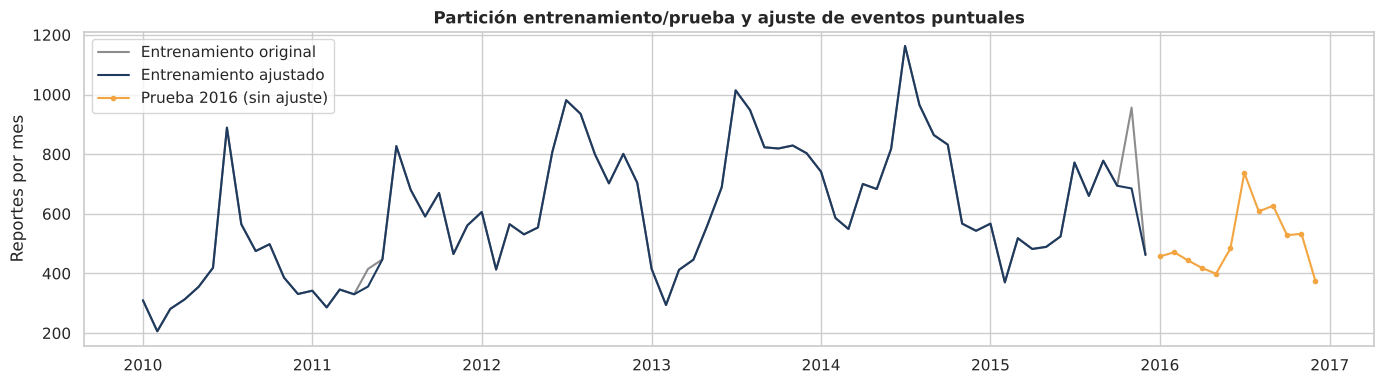

In [39]:
diaria = diaria_total.asfreq("D", fill_value=0).astype(float)
mediana_movil = diaria.rolling(31, center=True, min_periods=15).median()
es_festivo_d = diaria.index.strftime("%m-%d").isin(["07-04", "12-31", "01-01"])
evento = (diaria > 5 * mediana_movil) & (~es_festivo_d) & (diaria.index <= pd.Timestamp("2015-12-31"))
print("Días ajustados en el entrenamiento:")
display(pd.DataFrame({"reportes": diaria[evento], "mediana_31d": mediana_movil[evento].round(1)}))

diaria_aj = diaria.where(~evento, mediana_movil.round())
y_full_aj = diaria_aj.resample("MS").sum().asfreq("MS")
y_train_aj = y_full_aj.loc[:FIN_TRAIN]
print(f"Reportes retirados del entrenamiento: {int((diaria - diaria_aj).sum())} "
      f"({(diaria - diaria_aj).sum() / y_train.sum():.2%} del total de entrenamiento)")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_train.index, y_train, color=GRIS, label="Entrenamiento original")
ax.plot(y_train_aj.index, y_train_aj, color=AZUL, label="Entrenamiento ajustado")
ax.plot(y_test.index, y_test, color=AMBAR, marker="o", ms=3, label="Prueba 2016 (sin ajuste)")
ax.set(title="Partición entrenamiento/prueba y ajuste de eventos puntuales", ylabel="Reportes por mes")
ax.legend()
guardar_fig("fig10_particion_ajuste")

## 4.3 Verificación de supuestos: descomposición, estacionariedad (ADF) y ACF/PACF

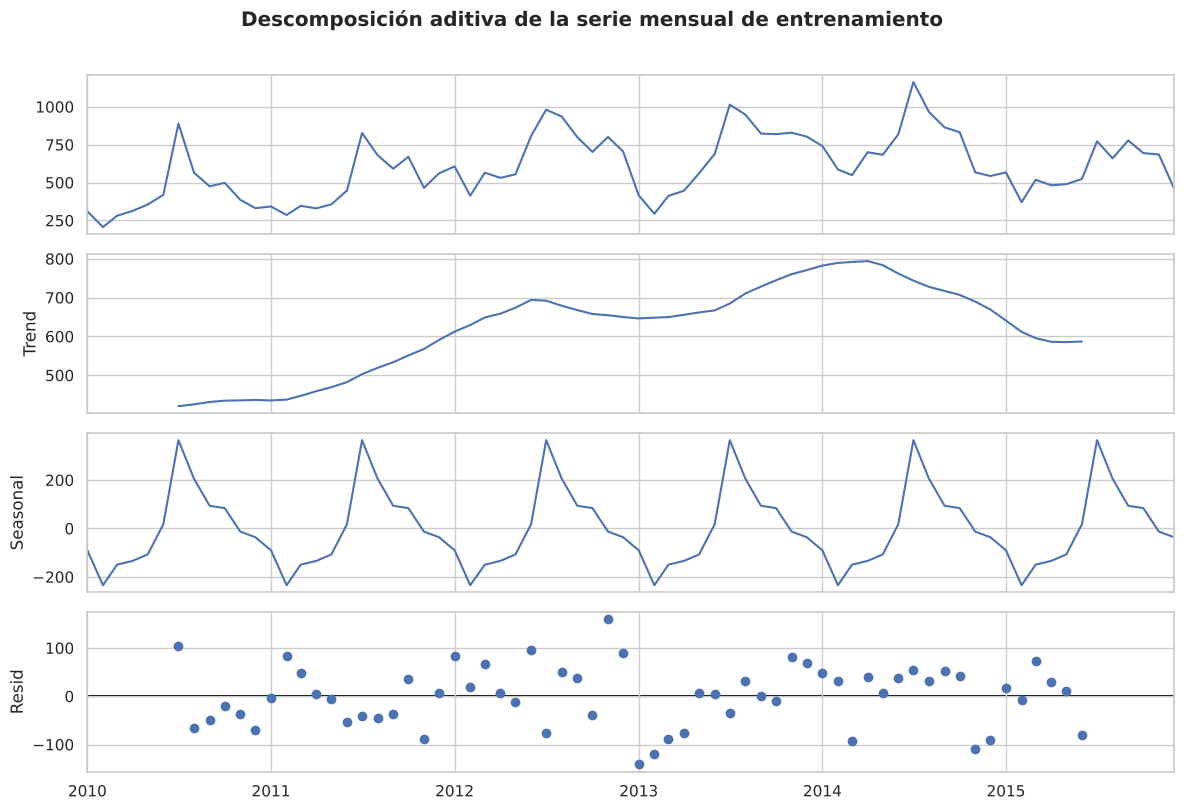

Fuerza de la estacionalidad: 0.87 | fuerza de la tendencia: 0.79 (0 = nula, 1 = máxima)


In [40]:
descomp = seasonal_decompose(y_train_aj, model="additive", period=S)
fig = descomp.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Descomposición aditiva de la serie mensual de entrenamiento", y=1.01, fontweight="bold")
plt.figure(fig.number)                                   # asegura que se guarde esta figura
guardar_fig("fig11_descomposicion")

fuerza_est = max(0, 1 - descomp.resid.var() / (descomp.seasonal + descomp.resid).var())
fuerza_tend = max(0, 1 - descomp.resid.var() / (descomp.trend + descomp.resid).var())
print(f"Fuerza de la estacionalidad: {fuerza_est:.2f} | fuerza de la tendencia: {fuerza_tend:.2f} (0 = nula, 1 = máxima)")

,serie,estadistico_ADF,p_valor,rezagos,n,conclusion
0,Original,-1.807,0.377,12,59,No estacionaria
1,Primera diferencia (d=1),-1.864,0.349,12,58,No estacionaria
2,Diferencia estacional (D=1),-2.704,0.073,8,51,No estacionaria
3,d=1 y D=1,-4.796,0.000,3,55,Estacionaria


Órdenes de diferenciación elegidos: d = 1, D = 1


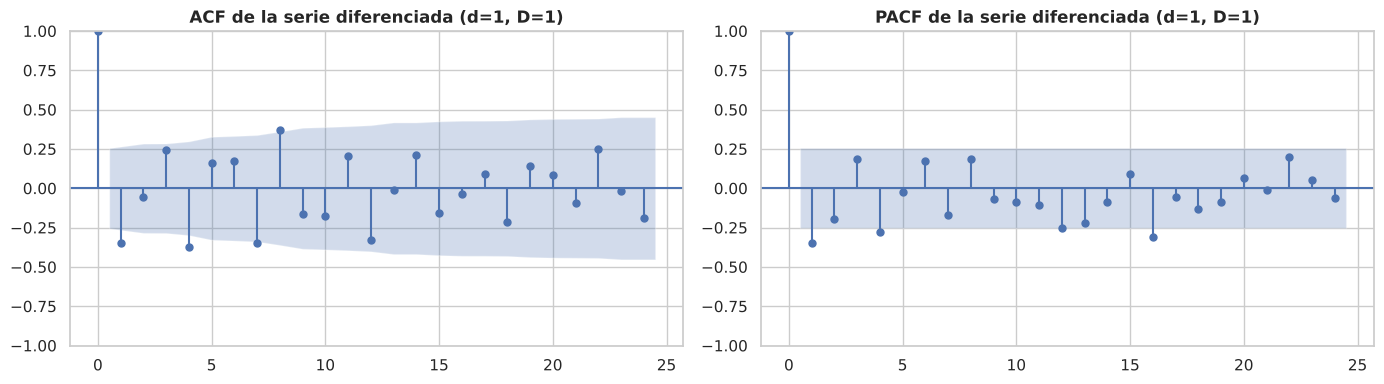

In [41]:
def prueba_adf(serie, nombre):
    est, p, rezagos, nobs, *_ = adfuller(serie.dropna(), autolag="AIC")
    return {"serie": nombre, "estadistico_ADF": est, "p_valor": p, "rezagos": rezagos, "n": nobs,
            "conclusion": "Estacionaria" if p < 0.05 else "No estacionaria"}

tabla_adf = pd.DataFrame([
    prueba_adf(y_train_aj, "Original"),
    prueba_adf(y_train_aj.diff(), "Primera diferencia (d=1)"),
    prueba_adf(y_train_aj.diff(S), "Diferencia estacional (D=1)"),
    prueba_adf(y_train_aj.diff(S).diff(), "d=1 y D=1"),
])
display(tabla_adf)

# Regla de decisión: siempre D=1 (estacionalidad fuerte); d=1 solo si la diferencia estacional no basta
D = 1
d = 0 if tabla_adf.loc[2, "p_valor"] < 0.05 else 1
print(f"Órdenes de diferenciación elegidos: d = {d}, D = {D}")
serie_estacionaria = y_train_aj.diff(S).diff() if d == 1 else y_train_aj.diff(S)
serie_estacionaria = serie_estacionaria.dropna()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(serie_estacionaria, lags=24, ax=ax[0])
plot_pacf(serie_estacionaria, lags=24, ax=ax[1], method="ywm")
ax[0].set_title(f"ACF de la serie diferenciada (d={d}, D={D})")
ax[1].set_title(f"PACF de la serie diferenciada (d={d}, D={D})")
guardar_fig("fig12_acf_pacf")

**Interpretación.** La prueba ADF indica si la serie necesita diferenciarse. Con la regla documentada (D = 1 por la estacionalidad fuerte; d = 1 solo si la diferencia estacional no basta), el cuaderno fija los órdenes `d` y `D`. En los gráficos ACF y PACF de la serie diferenciada, los rezagos significativos (fuera de la banda azul) sugieren el rango de órdenes a explorar: un corte en el rezago 1 de la ACF apunta a un término MA(1), un corte en la PACF apunta a AR(1), y un pico en el rezago 12 apunta a un término estacional. Por eso la búsqueda en malla explora p, q ∈ {0, 1, 2} y P, Q ∈ {0, 1}.

**Resultado.** La serie mensual de entrenamiento **no es estacionaria** (ADF = −1,81; p = 0,377). La primera diferencia sola no basta (p = 0,349) y la diferencia estacional sola tampoco (p = 0,073 > 0,05), de modo que, según la regla, se fija **d = 1 y D = 1**; con ambas diferencias la serie sí es estacionaria (ADF = −4,80; p < 0,001). Advertencia: con 51 a 59 observaciones la prueba ADF tiene poca potencia y el p de 0,073 queda cerca del umbral, por lo que los órdenes se validan después con los residuos y los criterios de información. En los correlogramas, la ACF tiene un rezago 1 negativo (≈ −0,35) por fuera de la banda, compatible con un término MA(1), y el rezago estacional 12 (≈ −0,33) queda dentro de la banda: después de diferenciar no queda una señal estacional clara. Hay valores aislados en los rezagos 4 y 7–8 sin patrón, por lo que se explora una malla de órdenes en lugar de fijar uno solo. La descomposición aditiva (Figura 11) arroja una fuerza de la estacionalidad de 0,87 y una fuerza de la tendencia de 0,79: ambos componentes son relevantes.

## 4.4 Funciones de los modelos

In [42]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    e = real - pred
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)), "MAPE": np.mean(np.abs(e) / real) * 100}

def pron_ingenuo(y_tr, h, s):
    """Ingenuo estacional: repite el último ciclo observado."""
    return np.resize(y_tr.iloc[-s:].to_numpy(), h)

def ajustar_hw(y_tr, s, configs=None):
    """Holt-Winters: elige la configuración con menor AICc en el entrenamiento."""
    if configs is None:
        configs = [(t, dmp, est) for t in (None, "add") for dmp in ((False, True) if t else (False,))
                   for est in ("add", "mul")]
    resultados = []
    for t, dmp, est in configs:
        try:
            with _w.catch_warnings():
                _w.simplefilter("ignore")
                res = ExponentialSmoothing(y_tr, trend=t, damped_trend=dmp, seasonal=est, seasonal_periods=s,
                                           initialization_method="estimated").fit(optimized=True)
            resultados.append({"tendencia": str(t), "amortiguada": dmp, "estacional": est, "AICc": res.aicc, "_res": res})
        except Exception as err:
            print("HW omitido", (t, dmp, est), type(err).__name__)
    tabla = pd.DataFrame(resultados).sort_values("AICc").reset_index(drop=True)
    return tabla.loc[0, "_res"], tabla.drop(columns="_res")

def ljung_box(resid, lags, model_df=0):
    lb = acorr_ljungbox(resid, lags=lags, model_df=model_df)
    if not isinstance(lb, pd.DataFrame):                     # compatibilidad con versiones antiguas
        lb = pd.DataFrame({"lb_stat": lb[0], "lb_pvalue": lb[1]}, index=lags)
    return lb

def ajustar_sarima(y_tr, d, D, s):
    """SARIMA: malla de órdenes, ordenada por AIC; se elige el de menor AIC con residuos blancos (Ljung-Box)."""
    resultados = []
    for p in range(3):
        for q in range(3):
            for P in range(2):
                for Q in range(2):
                    try:
                        with _w.catch_warnings():
                            _w.simplefilter("ignore")
                            res = SARIMAX(y_tr, order=(p, d, q), seasonal_order=(P, D, Q, s)).fit(disp=False)
                        resid = res.resid.iloc[d + D * s:]
                        lb_p = ljung_box(resid, [12], model_df=p + q + P + Q)["lb_pvalue"].iloc[0]
                        resultados.append({"orden": (p, d, q), "orden_estacional": (P, D, Q, s), "AIC": res.aic,
                                           "LjungBox_p12": lb_p, "_res": res})
                    except Exception as err:
                        print("SARIMA omitido", (p, d, q, P, Q), type(err).__name__)
    tabla = pd.DataFrame(resultados).sort_values("AIC").reset_index(drop=True)
    validos = tabla[tabla["LjungBox_p12"] > 0.05]
    elegido = validos.index[0] if len(validos) else 0
    return tabla.loc[elegido, "_res"], tabla.drop(columns="_res"), elegido

def features_mensual(y):
    X = pd.DataFrame(index=y.index)
    X["mes"] = y.index.month
    X["t"] = np.arange(len(y))
    X["lag_12"] = y.shift(12)
    X["fines_de_semana"] = [int((pd.date_range(f, f + pd.offsets.MonthEnd(0)).dayofweek >= 5).sum()) for f in y.index]
    return X

def pron_rf(y_hist, fin_train, h, features, n_lag):
    """Random Forest con variables de calendario; los rezagos >= h evitan fuga de información."""
    X = features(y_hist)
    entreno = X.loc[:fin_train].iloc[n_lag:]
    rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=RANDOM_STATE)
    rf.fit(entreno, y_hist.loc[entreno.index])
    futuro = X.loc[X.index > pd.Timestamp(fin_train)].iloc[:h]
    return rf.predict(futuro), rf, entreno.columns

## 4.5 Elección del modelo principal por validación interna (entrena 2010–2014, valida 2015)

In [43]:
FIN_SUB, INI_VAL, FIN_VAL = "2014-12-01", "2015-01-01", "2015-12-01"
y_sub, y_val = y_full_aj.loc[:FIN_SUB], y_full_aj.loc[INI_VAL:FIN_VAL]

hw_sub, _ = ajustar_hw(y_sub, S)
sar_sub, _, _ = ajustar_sarima(y_sub, d, D, S)
validacion = pd.DataFrame({
    "Ingenuo estacional": metricas(y_val, pron_ingenuo(y_sub, 12, S)),
    "Holt-Winters": metricas(y_val, hw_sub.forecast(12)),
    "SARIMA": metricas(y_val, sar_sub.get_forecast(12).predicted_mean),
}).T
display(validacion.round(2))
PRINCIPAL = "SARIMA" if validacion.loc["SARIMA", "MAPE"] <= validacion.loc["Holt-Winters", "MAPE"] else "Holt-Winters"
print(f"Modelo principal elegido por MAPE de validación (2015): {PRINCIPAL}")

,MAE,RMSE,MAPE
Ingenuo estacional,187.170,212.590,33.220
Holt-Winters,76.480,97.590,12.550
SARIMA,78.370,99.890,13.170


Modelo principal elegido por MAPE de validación (2015): Holt-Winters


## 4.6 Ajuste final con 2010–2015 y parámetros documentados

In [44]:
# --- Holt-Winters ---
hw_res, tabla_hw = ajustar_hw(y_train_aj, S)
print("Holt-Winters: configuraciones ordenadas por AICc")
display(tabla_hw.round(2))
param_hw = {k: v for k, v in hw_res.params.items() if np.isscalar(v)}
print("Parámetros estimados:", {k: round(float(v), 4) for k, v in param_hw.items()
                                 if k in ("smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend")})

# --- SARIMA ---
sar_res, tabla_sar, idx_sar = ajustar_sarima(y_train_aj, d, D, S)
print("\nSARIMA: 10 mejores órdenes por AIC")
display(tabla_sar.head(10).round(3))
print(f"Elegido: SARIMA{tabla_sar.loc[idx_sar, 'orden']}x{tabla_sar.loc[idx_sar, 'orden_estacional']} "
      f"(posición {idx_sar + 1} por AIC; primer modelo con Ljung-Box p > 0,05)")
print(sar_res.summary().tables[1])

Holt-Winters: configuraciones ordenadas por AICc


,tendencia,amortiguada,estacional,AICc
0,None,False,add,663.930
1,add,False,add,670.770
2,None,False,mul,673.130
3,add,True,add,674.020
4,add,False,mul,679.640
5,add,True,mul,681.370


Parámetros estimados: {'smoothing_level': 0.5552, 'smoothing_trend': nan, 'smoothing_seasonal': 0.0, 'damping_trend': nan}



SARIMA: 10 mejores órdenes por AIC


,orden,orden_estacional,AIC,LjungBox_p12
0,"(0, 1, 1)","(0, 1, 1, 12)",719.359,0.230
1,"(2, 1, 2)","(0, 1, 1, 12)",721.026,0.224
2,"(0, 1, 2)","(0, 1, 1, 12)",721.144,0.139
3,"(1, 1, 1)","(0, 1, 1, 12)",721.154,0.138
4,"(2, 1, 0)","(0, 1, 1, 12)",721.249,0.221
5,"(0, 1, 1)","(1, 1, 1, 12)",721.358,0.172
6,"(1, 1, 0)","(0, 1, 1, 12)",721.688,0.076
7,"(2, 1, 1)","(0, 1, 1, 12)",721.828,0.313
8,"(2, 1, 2)","(1, 1, 1, 12)",722.292,0.344
9,"(0, 1, 2)","(1, 1, 1, 12)",723.131,0.104


Elegido: SARIMA(0, 1, 1)x(0, 1, 1, 12) (posición 1 por AIC; primer modelo con Ljung-Box p > 0,05)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4412      0.124     -3.557      0.000      -0.684      -0.198
ma.S.L12      -0.9944     15.535     -0.064      0.949     -31.442      29.453
sigma2      7319.8834   1.13e+05      0.065      0.948   -2.15e+05    2.29e+05


In [45]:
# --- Pronósticos sobre 2016 ---
H = len(y_test)
pred = pd.DataFrame(index=y_test.index)
pred["Ingenuo estacional"] = pron_ingenuo(y_train_aj, H, S)
pred["Holt-Winters"] = hw_res.forecast(H).to_numpy()
fc_sar = sar_res.get_forecast(H)
pred["SARIMA"] = fc_sar.predicted_mean.to_numpy()
ic_sar = fc_sar.conf_int(alpha=0.05)
pred["rf"], rf_mod, rf_cols = pron_rf(y_full_aj.where(y_full_aj.index <= FIN_TRAIN, np.nan).fillna(0),
                                      FIN_TRAIN, H, features_mensual, 12)
pred = pred.rename(columns={"rf": "Random Forest"})
# Nota: la serie de entrada al RF tiene 2016 en 0 (desconocido); solo se usan t, mes, fines de semana y lag_12 (2015).

# Intervalos al 95 % del modelo principal
if PRINCIPAL == "SARIMA":
    li, ls = ic_sar.iloc[:, 0].to_numpy(), ic_sar.iloc[:, 1].to_numpy()
else:   # aproximación para Holt-Winters: ± 1,96 · desviación de los residuos
    sd = np.std(hw_res.resid)
    li, ls = pred["Holt-Winters"] - 1.96 * sd, pred["Holt-Winters"] + 1.96 * sd
li, ls = np.asarray(li, dtype=float), np.asarray(ls, dtype=float)

importancias = pd.Series(rf_mod.feature_importances_, index=rf_cols).sort_values(ascending=False)
print("Importancia de variables del Random Forest:")
display(importancias.round(3).to_frame("importancia"))

Importancia de variables del Random Forest:


,importancia
mes,0.431
lag_12,0.315
t,0.233
fines_de_semana,0.021


**Interpretación del ajuste.** *Holt-Winters:* la mejor configuración por AICc (663,9) es **sin tendencia y con estacionalidad aditiva** (la siguiente, con tendencia aditiva, tiene 670,8). El nivel se suaviza con α = 0,555 y el factor estacional queda fijo (γ = 0,0): el patrón estacional es estable durante los seis años. La tendencia no mejora el ajuste porque el volumen sube hasta 2014 y baja después. *SARIMA:* el mejor orden por AIC (719,4) es SARIMA(0,1,1)×(0,1,1)₁₂ y supera la prueba de Ljung-Box (p = 0,230). Su coeficiente MA estacional es −0,994 con un error estándar muy grande (15,5), es decir, está en el borde de no invertibilidad: es la señal clásica de que la estacionalidad es casi determinista y de que la diferenciación estacional puede estar sobrediferenciando. Esto coincide con γ = 0 en Holt-Winters. *Random Forest:* el mes (0,43), el rezago 12 (0,32) y el índice temporal *t* (0,23) concentran la importancia; los fines de semana del mes (0,02) casi no aportan.

## 4.7 Diagnóstico de residuos (Ljung-Box)
Un modelo bien especificado deja residuos sin autocorrelación (ruido blanco). Si quedan patrones, el modelo está desaprovechando información. La hipótesis nula de Ljung-Box es "no hay autocorrelación hasta el rezago *k*"; se busca p > 0,05 (criterio CE3).

lb_stat  lb_pvalue
SARIMA       6     5.834      0.212
             12   12.882      0.230
             24   24.546      0.319
Holt-Winters 6     7.036      0.318
             12   18.645      0.097
             24   38.919      0.028

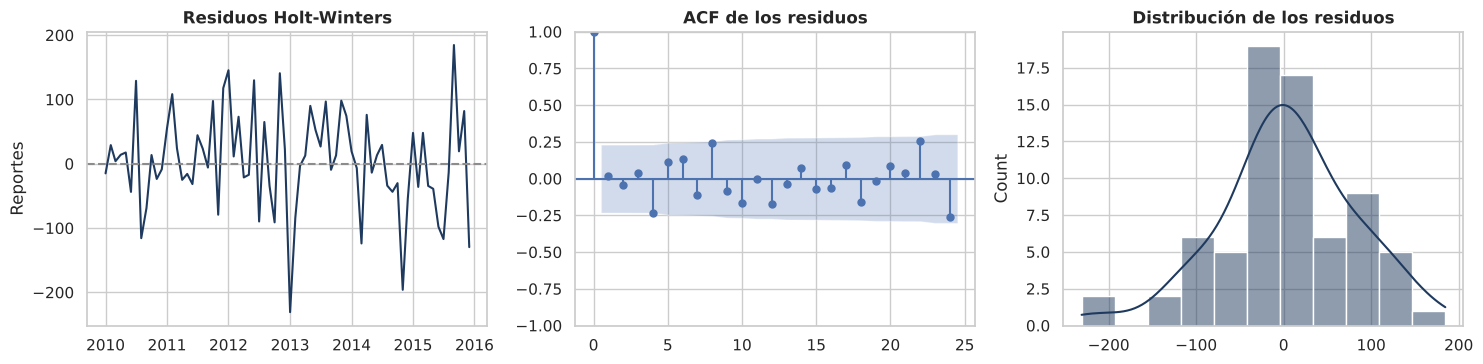

Shapiro-Wilk de los residuos: p = 0.420


In [46]:
p_, d_, q_ = tabla_sar.loc[idx_sar, "orden"]
P_, D_, Q_, _ = tabla_sar.loc[idx_sar, "orden_estacional"]
resid_sar = sar_res.resid.iloc[d + D * S:]
resid_hw = hw_res.resid
lb_tabla = pd.concat({
    "SARIMA": ljung_box(resid_sar, [6, 12, 24], model_df=p_ + q_ + P_ + Q_),
    "Holt-Winters": ljung_box(resid_hw, [6, 12, 24]),
}).round(4)
display(lb_tabla)
lb_principal = lb_tabla.loc[(PRINCIPAL, 12), "lb_pvalue"]

resid_p = resid_sar if PRINCIPAL == "SARIMA" else resid_hw
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(resid_p.index, resid_p, color=AZUL); ax[0].axhline(0, color=GRIS, ls="--")
ax[0].set(title=f"Residuos {PRINCIPAL}", ylabel="Reportes")
plot_acf(resid_p, lags=24, ax=ax[1]); ax[1].set_title("ACF de los residuos")
sns.histplot(resid_p, kde=True, color=AZUL, ax=ax[2]); ax[2].set_title("Distribución de los residuos")
guardar_fig("fig13_residuos")
print(f"Shapiro-Wilk de los residuos: p = {stats.shapiro(resid_p).pvalue:.3f}")

**Interpretación (CE3).** El modelo principal (Holt-Winters) deja residuos sin autocorrelación significativa en los rezagos 6 (p = 0,318) y 12 (p = 0,097), por lo que **CE3 se cumple en el rezago 12 definido en la fase 1, aunque con poco margen**. En el rezago 24, en cambio, p = 0,028: queda autocorrelación de largo plazo (en la ACF de los residuos, los rezagos 4 y 24 rozan la banda). SARIMA pasa la prueba en los tres rezagos (p ≥ 0,212), pero, como se verá en la fase 5, pronostica peor el 2016. Los residuos de Holt-Winters son compatibles con una distribución normal (Shapiro-Wilk, p = 0,420), lo que respalda los intervalos aproximados de ±1,96 desviaciones estándar.

## 4.8 Variante semanal
La serie semanal (52 semanas por ciclo) es más ruidosa y los festivos caen en semanas distintas cada año. Un SARIMA con período 52 es costoso de estimar y numéricamente inestable con 6 años de datos; para períodos estacionales largos, Hyndman y Athanasopoulos (2021) recomiendan alternativas como Holt-Winters o regresión con variables de calendario. Se comparan el ingenuo estacional (s = 52), Holt-Winters (con y sin tendencia amortiguada; se elige por AICc) y un Random Forest que incluye una marca de semana con festivo.

*Nota:* la última semana de entrenamiento (28-dic-2015 a 3-ene-2016) incluye tres días de 2016. El efecto es marginal (1 de 364 semanas) pero se declara como limitación (sección 5.4).

In [47]:
SW = 52
FIN_TRAIN_W = "2015-12-28"
yw = serie_semanal.astype(float)
# El mismo ajuste de eventos que en la serie mensual
yw_aj = diaria_aj.loc["2010-01-04":"2016-12-25"].resample("W-SUN").sum()
yw_aj.index = yw_aj.index - pd.Timedelta(days=6)
yw_aj = yw_aj.asfreq("W-MON")
yw_train, yw_test = yw_aj.loc[:FIN_TRAIN_W], yw.loc[FIN_TRAIN_W:].iloc[1:]
print(f"Semanas de entrenamiento: {len(yw_train)} | prueba: {len(yw_test)}")

def features_semanal(y):
    X = pd.DataFrame(index=y.index)
    X["semana_anio"] = y.index.isocalendar().week.astype(int).to_numpy()
    X["t"] = np.arange(len(y))
    X["lag_52"] = y.shift(52)
    dias = [pd.date_range(f, periods=7) for f in y.index]
    X["festivo"] = [int(any(dd.strftime("%m-%d") in ("07-04", "12-31", "01-01") for dd in r)) for r in dias]
    return X

HW_ = len(yw_test)
pred_w = pd.DataFrame(index=yw_test.index)
pred_w["Ingenuo estacional"] = pron_ingenuo(yw_train, HW_, SW)
hw_w, tabla_hw_w = ajustar_hw(yw_train, SW, configs=[("add", True, "add"), (None, False, "add")])
pred_w["Holt-Winters"] = hw_w.forecast(HW_).to_numpy()
pred_w["Random Forest"], _, _ = pron_rf(yw_aj.where(yw_aj.index <= FIN_TRAIN_W, 0), FIN_TRAIN_W, HW_, features_semanal, 52)
display(tabla_hw_w.round(2))

Semanas de entrenamiento: 313 | prueba: 51


/tmp/ipykernel_225/3135514979.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  yw_aj.index = yw_aj.index - pd.Timedelta(days=6)


,tendencia,amortiguada,estacional,AICc
0,None,False,add,"2,268.360"
1,add,True,add,"2,274.390"


## 4.9 Modelo complementario: segmentación geográfica con K-means
**Objetivo:** identificar zonas de concentración para que el centro asigne analistas por región. Se usa K-means sobre `lat` y `lng` (ambas en grados, así que no se escalan) y se elige *k* entre 3 y 10 con el **coeficiente de silueta**. Este se calcula sobre una muestra fija de 10.000 puntos (`random_state`), porque su costo crece con el cuadrado de *n*.

[12] h) Segmentación geográfica (K-means): (49803, 27) -> (49803, 28) | afectados: 49803


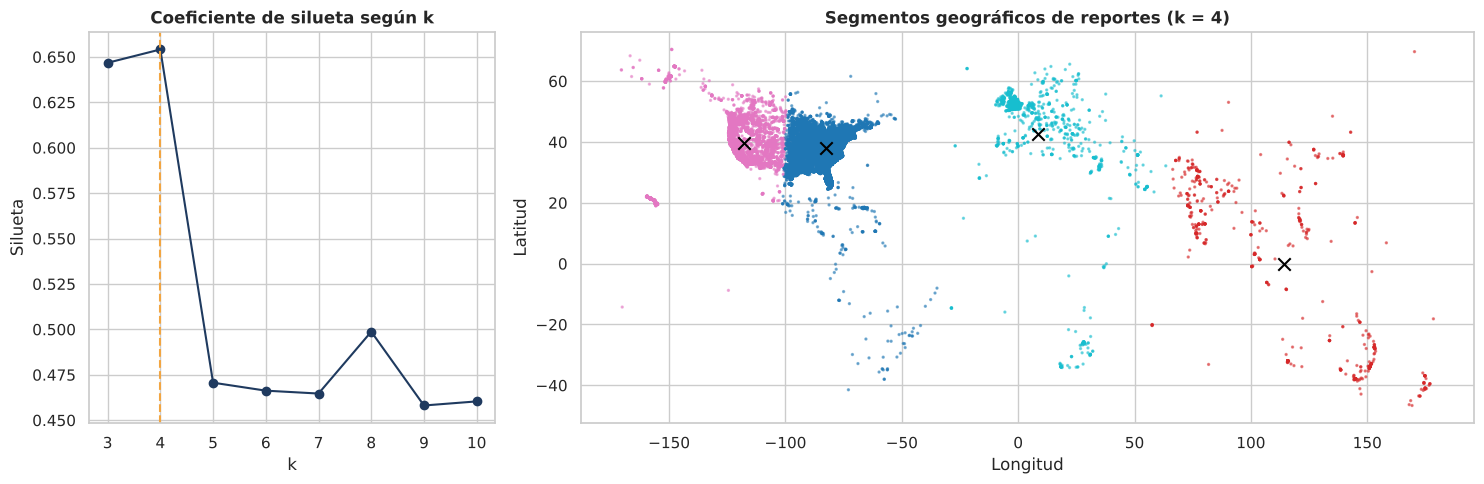

Silueta con k = 4: 0.654


,reportes,lat_centro,lng_centro,pais_principal,pct
cluster_geo,,,,,
1,32558,37.880,-82.610,USA,65.400
2,589,-0.030,114.120,AUS,1.200
3,15419,39.690,-117.820,USA,31.000
4,1237,42.560,8.330,GBR,2.500


In [48]:
X_geo = df[["lat", "lng"]].to_numpy()
siluetas = {}
for k in range(3, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_geo)
    siluetas[k] = silhouette_score(X_geo, km.labels_, sample_size=10_000, random_state=RANDOM_STATE)
K_OPT = max(siluetas, key=siluetas.get)
km_final = KMeans(n_clusters=K_OPT, n_init=10, random_state=RANDOM_STATE).fit(X_geo)

antes = df.copy()
df["cluster_geo"] = km_final.labels_ + 1
log_step("h) Segmentación geográfica (K-means)", antes, df, f"cluster_geo con k = {K_OPT} (máxima silueta)",
         afectados=len(df))

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2.2]})
ax[0].plot(list(siluetas), list(siluetas.values()), marker="o", color=AZUL)
ax[0].axvline(K_OPT, color=AMBAR, ls="--"); ax[0].set(title="Coeficiente de silueta según k", xlabel="k", ylabel="Silueta")
sc = ax[1].scatter(df["lng"], df["lat"], c=df["cluster_geo"], cmap="tab10", s=2, alpha=0.5)
ax[1].scatter(km_final.cluster_centers_[:, 1], km_final.cluster_centers_[:, 0], c="black", marker="x", s=80)
ax[1].set(title=f"Segmentos geográficos de reportes (k = {K_OPT})", xlabel="Longitud", ylabel="Latitud")
guardar_fig("fig14_clusters_geo")

resumen_cluster = (df.groupby("cluster_geo").agg(reportes=("id", "size"), lat_centro=("lat", "mean"), lng_centro=("lng", "mean"),
                                                 pais_principal=("pais", lambda s: s.mode().iloc[0]))
                   .assign(pct=lambda t: (t["reportes"] / len(df) * 100).round(1)))
print(f"Silueta con k = {K_OPT}: {siluetas[K_OPT]:.3f}")
display(resumen_cluster.round(2))
uap_procesado = exportar_fact(df[COLUMNAS_FACT + ["cluster_geo"]])     # se reexporta con la nueva columna

**Interpretación.** El coeficiente de silueta varía entre −1 y 1. Valores por encima de 0,5 indican segmentos bien separados. Con *k* = 4 la silueta es 0,654, una estructura clara, aunque *k* = 3 obtiene casi el mismo valor (0,647). Se elige *k* = 4 porque la diferencia es mínima y separa mejor la operación. Los cuatro segmentos son: **EE. UU. este y centro, más el este de Canadá y Latinoamérica** (65,4 % de los reportes), **EE. UU. oeste, más Alaska y Hawái** (31,0 %), **Europa y África** (2,5 %) y **Asia y Oceanía** (1,2 %). Para el centro de recepción, esto sugiere dos equipos regionales en EE. UU. con una proporción de casi 2 a 1, más un equipo pequeño para el resto del mundo. La división este-oeste también coincide con husos horarios distintos, lo que reparte el pico nocturno. **Limitación:** K-means asume grupos esféricos y usa distancia euclidiana en grados, que se distorsiona lejos del ecuador. Para la asignación de analistas basta, pero no es una segmentación geodésica.

---
# FASE 5. Evaluación

## 5.1 Métricas comparativas en el conjunto de prueba (2016)

In [49]:
def tabla_metricas(real, predicciones, granularidad):
    filas = []
    base = metricas(real, predicciones["Ingenuo estacional"])
    for modelo in predicciones.columns:
        m = metricas(real, predicciones[modelo])
        m["mejora_MAE_vs_ingenuo_pct"] = (base["MAE"] - m["MAE"]) / base["MAE"] * 100
        filas.append({"granularidad": granularidad, "modelo": modelo, **m})
    return pd.DataFrame(filas)

metricas_modelo = pd.concat([tabla_metricas(y_test, pred, "Mensual"),
                             tabla_metricas(yw_test, pred_w, "Semanal")], ignore_index=True)
metricas_modelo["principal"] = (metricas_modelo["granularidad"] == "Mensual") & (metricas_modelo["modelo"] == PRINCIPAL)
metricas_modelo["cumple_CE1_MAPE"] = metricas_modelo["MAPE"] <= 20
metricas_modelo["cumple_CE2_MAE"] = metricas_modelo["mejora_MAE_vs_ingenuo_pct"] >= 10
metricas_modelo.round(2)

,granularidad,modelo,MAE,RMSE,MAPE,mejora_MAE_vs_ingenuo_pct,principal,cumple_CE1_MAPE,cumple_CE2_MAE
0,Mensual,Ingenuo estacional,93.500,102.690,19.070,0.000,False,True,False
1,Mensual,Holt-Winters,87.340,102.560,17.230,6.590,True,True,False
2,Mensual,SARIMA,100.630,116.140,19.860,-7.630,False,True,False
3,Mensual,Random Forest,96.550,112.200,21.230,-3.260,False,False,False
4,Semanal,Ingenuo estacional,29.180,41.730,25.070,0.000,False,False,False
5,Semanal,Holt-Winters,26.430,41.400,23.430,9.400,False,False,False
6,Semanal,Random Forest,27.380,34.080,25.570,6.150,False,False,False


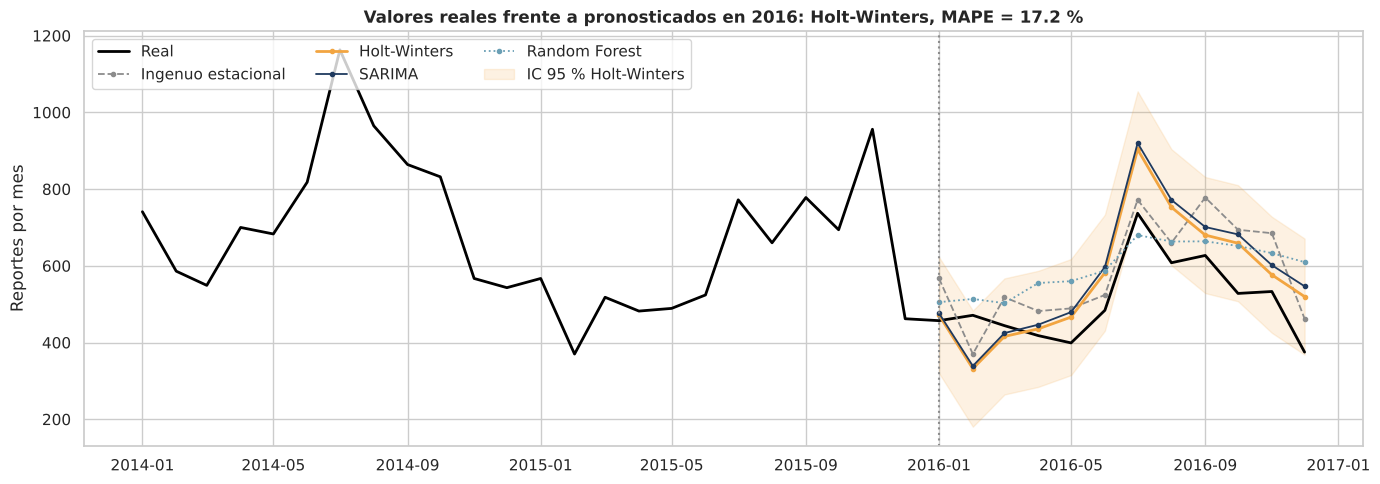

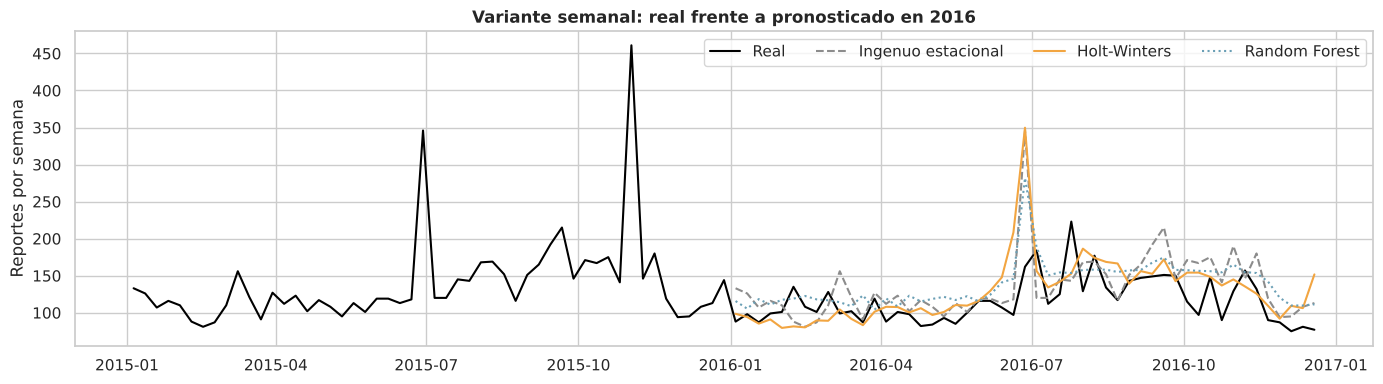

In [50]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_full.loc["2014-01-01":].index, y_full.loc["2014-01-01":], color="black", lw=2, label="Real")
estilos = {"Ingenuo estacional": (GRIS, "--"), "Holt-Winters": (AMBAR, "-"), "SARIMA": (AZUL, "-"), "Random Forest": ("#6A9FB5", ":")}
for modelo, (c, ls_) in estilos.items():
    ax.plot(pred.index, pred[modelo], color=c, ls=ls_, lw=2 if modelo == PRINCIPAL else 1.3, marker="o", ms=3, label=modelo)
ax.fill_between(pred.index, li, ls, color=AZUL if PRINCIPAL == "SARIMA" else AMBAR, alpha=0.15, label=f"IC 95 % {PRINCIPAL}")
ax.axvline(pd.Timestamp(INI_TEST), color=GRIS, ls=":")
mape_p = metricas_modelo.query("principal")["MAPE"].iloc[0]
ax.set(title=f"Valores reales frente a pronosticados en 2016: {PRINCIPAL}, MAPE = {mape_p:.1f} %", ylabel="Reportes por mes")
ax.legend(ncol=3, loc="upper left")
guardar_fig("fig15_real_vs_pronostico")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(yw.loc["2015-01-01":].index, yw.loc["2015-01-01":], color="black", lw=1.5, label="Real")
for modelo, (c, ls_) in estilos.items():
    if modelo in pred_w:
        ax.plot(pred_w.index, pred_w[modelo], color=c, ls=ls_, label=modelo)
ax.set(title="Variante semanal: real frente a pronosticado en 2016", ylabel="Reportes por semana"); ax.legend(ncol=4)
guardar_fig("fig16_real_vs_pronostico_semanal")

## 5.2 Contraste con los criterios de éxito de la fase 1

In [51]:
fila_p = metricas_modelo.query("principal").iloc[0]
mejor_semanal = metricas_modelo.query("granularidad == 'Semanal'").sort_values("MAPE").iloc[0]
criterios = pd.DataFrame([
    ("CE1", "MAPE del modelo principal ≤ 20 %", f"{fila_p['MAPE']:.1f} %", fila_p["MAPE"] <= 20),
    ("CE1 ideal", "MAPE ≤ 15 %", f"{fila_p['MAPE']:.1f} %", fila_p["MAPE"] <= 15),
    ("CE2", "Mejora del MAE ≥ 10 % frente al ingenuo estacional", f"{fila_p['mejora_MAE_vs_ingenuo_pct']:.1f} %",
     fila_p["mejora_MAE_vs_ingenuo_pct"] >= 10),
    ("CE3", "Residuos sin autocorrelación (Ljung-Box, rezago 12, p > 0,05)", f"p = {lb_principal:.3f}", lb_principal > 0.05),
    ("CE3 (informativo)", "Ljung-Box en el rezago 24, p > 0,05", f"p = {lb_tabla.loc[(PRINCIPAL, 24), 'lb_pvalue']:.3f}",
     lb_tabla.loc[(PRINCIPAL, 24), "lb_pvalue"] > 0.05),
    ("Variante semanal", "Mejor MAPE semanal ≤ 20 %", f"{mejor_semanal['modelo']}: {mejor_semanal['MAPE']:.1f} %",
     mejor_semanal["MAPE"] <= 20),
], columns=["criterio", "descripcion", "resultado", "cumple"])
criterios["veredicto"] = np.where(criterios["cumple"], "Se cumple", "No se cumple")
criterios.drop(columns="cumple")

,criterio,descripcion,resultado,veredicto
0,CE1,MAPE del modelo principal ≤ 20 %,17.2 %,Se cumple
1,CE1 ideal,MAPE ≤ 15 %,17.2 %,No se cumple
2,CE2,Mejora del MAE ≥ 10 % frente al ingenuo estaci...,6.6 %,No se cumple
3,CE3,"Residuos sin autocorrelación (Ljung-Box, rezag...",p = 0.097,Se cumple
4,CE3 (informativo),"Ljung-Box en el rezago 24, p > 0,05",p = 0.028,No se cumple
5,Variante semanal,Mejor MAPE semanal ≤ 20 %,Holt-Winters: 23.4 %,No se cumple


In [52]:
# Errores mensuales del modelo principal en 2016 (para ubicar dónde falla y si hay sesgo)
err = pd.DataFrame({'real': y_test, 'pronostico': pred[PRINCIPAL]})
err['error'] = err['pronostico'] - err['real']                 # > 0: sobreestima
err['error_abs'] = err['error'].abs()
err['error_pct'] = err['error_abs'] / err['real'] * 100
display(err.round(1))
print(f"Sesgo medio (pronóstico − real): {err['error'].mean():+.1f} reportes/mes | meses sobreestimados: "
      f"{(err['error'] > 0).sum()} de {len(err)}")
print(f"Cobertura empírica del IC 95 %: {((y_test.to_numpy() >= li) & (y_test.to_numpy() <= ls)).mean():.0%} (esperado ≈ 95 %)")

,real,pronostico,error,error_abs,error_pct
fecha,,,,,
2016-01-01,457.000,471.500,14.500,14.500,3.200
2016-02-01,471.000,331.900,-139.100,139.100,29.500
2016-03-01,444.000,415.900,-28.100,28.100,6.300
2016-04-01,418.000,435.700,17.700,17.700,4.200
2016-05-01,399.000,466.300,67.300,67.300,16.900
2016-06-01,484.000,581.900,97.900,97.900,20.200
2016-07-01,737.000,903.500,166.500,166.500,22.600
2016-08-01,608.000,752.600,144.600,144.600,23.800
2016-09-01,627.000,680.100,53.100,53.100,8.500


Sesgo medio (pronóstico − real): +59.5 reportes/mes | meses sobreestimados: 10 de 12
Cobertura empírica del IC 95 %: 92% (esperado ≈ 95 %)


## 5.3 Interpretación en el contexto del negocio

- **Desempeño del principal.** El modelo principal, **Holt-Winters aditivo sin tendencia**, se equivoca en promedio en 87,3 reportes por mes (MAE; RMSE = 102,6) y su MAPE es 17,2 %. Sobre un volumen típico de unos 500 reportes mensuales en 2016 (la media de 2016 fue 507), eso equivale a un margen de ±87 reportes (±17 %) al planear el mes. Frente al ingenuo estacional (MAPE 19,1 %; MAE 93,5), que copia 2015 y por eso no capta que la caída continúa en 2016, el MAE baja **6,6 %**: es una mejora, pero menor que el 10 % exigido en CE2.
- **SARIMA.** Pese a tener el mejor AIC y residuos sin autocorrelación, pronostica peor que la referencia (MAE 100,6; MAPE 19,9 %; −7,6 % frente al ingenuo). Un buen ajuste dentro de la muestra no garantiza un buen pronóstico; además su coeficiente MA estacional está en el límite de invertibilidad (fase 4), señal de que diferenciar estacionalmente de más agrega ruido al pronóstico.
- **Dónde falla.** Según la Figura 15, las mayores desviaciones (del orden de 100 a 170 reportes) se dan en febrero (el modelo subestima: la demanda real no cayó tanto como el valle estacional) y en julio, agosto, octubre y diciembre (el modelo sobreestima: el pico de julio y el nivel del segundo semestre fueron menores que los aprendidos en 2010–2015, porque la caída iniciada en 2015 continuó). La tabla de errores por mes (celda anterior) permite verificar cada valor. El evento del 27-jul-2016 (reentrada de un cohete) es un pico puntual que ningún calendario anticipa.
- **Random Forest.** En la serie mensual es peor que el ingenuo estacional (MAPE 21,2 % frente a 19,1 %). Al ser un modelo basado en árboles **no puede extrapolar** niveles fuera del rango de entrenamiento, una limitación conocida con series cortas que tienen tendencia.
- **Semanal.** El mejor modelo semanal es Holt-Winters (MAPE 23,4 %; mejora del MAE de 9,4 % frente al ingenuo semanal, con MAPE de 25,1 %). El Random Forest semanal tiene MAPE de 25,6 % pero el **menor RMSE (34,1)**: la marca de semana con festivo le ayuda con los picos. El error semanal es mayor que el mensual, como se esperaba: al agregar por mes, los errores semanales se compensan. Para planear turnos semana a semana, el pronóstico debe complementarse con el calendario de festivos.

## 5.4 Limitaciones
1. **Objetivos de negocio supuestos:** no se tuvo acceso a los objetivos reales de NUFORC ni de otra organización. Los objetivos ON1–ON4 y los umbrales de éxito (CE1–CE2) son supuestos razonables del equipo, no requisitos de un usuario real; con requisitos reales podrían cambiar el modelo y los umbrales.
2. **Sesgo de notificación:** los reportes son voluntarios. La serie mide la *propensión a reportar* (exposición, difusión mediática, facilidad de acceso al formulario), no la frecuencia real de fenómenos. Un cambio en la visibilidad de NUFORC puede mover el nivel sin que cambie nada en el cielo.
3. **Serie corta:** 72 meses de entrenamiento equivalen a seis ciclos estacionales. Los parámetros estacionales se estiman con poca información y el conjunto de prueba es un solo año (12 puntos), de modo que el MAPE en la prueba es una estimación con alta varianza y la diferencia de 6,6 % en el MAE frente al ingenuo no es concluyente.
4. **Cambio de tendencia:** el máximo de 2014 y la caída posterior no tienen una variable explicativa en los datos; el modelo los aprende solo como nivel.
5. **Predominio de USA (90 %):** el modelo describe la demanda estadounidense. No debe usarse para otros países sin reentrenarlo.
6. **Festivos y eventos:** el 4 de julio se repite, pero con intensidad variable (de 170 a 274 reportes). Los eventos como misiles o reentradas de cohetes son imprevisibles; se ajustaron en el entrenamiento, pero en producción seguirán generando errores puntuales.
7. **Datos antiguos:** el periodo termina en 2016. Antes de usar el modelo para planear hoy, hay que reentrenarlo con datos recientes.
8. **Semana de traslape (variante semanal):** la última semana de entrenamiento incluye tres días de 2016; efecto marginal, pero no nulo.

## 5.5 Conclusión: ¿sirve el modelo para el uso previsto?
El modelo principal (Holt-Winters aditivo sin tendencia) **cumple CE1** (MAPE de 17,2 % ≤ 20 %, aunque no alcanza el ideal de 15 %) y **CE3 en el rezago 12** definido en la fase 1 (p = 0,097, con poco margen; en el rezago 24, p = 0,028), pero **no cumple CE2**: reduce el MAE solo 6,6 % frente al ingenuo estacional (umbral: 10 %).

La conclusión honesta es que el modelo **sirve como referencia para planear la capacidad mensual con un margen de error de ±17 %**, pero que con un año de prueba y una serie de 84 meses **no puede afirmarse que supere de forma clara** a la práctica ingenua. Su valor está en que captura bien la estacionalidad (pico de julio, valle de febrero) y en que entrega intervalos y un pronóstico para 2017. Recomendaciones: (1) usarlo para fijar el número base de analistas por mes, junto con reglas de calendario (refuerzo del 4 de julio de forma independiente al pronóstico); (2) reentrenarlo cada año; (3) ampliar la serie y añadir regresores externos (lanzamientos de cohetes, eventos mediáticos); y (4) validar con origen rodante cuando haya más años. Todo esto bajo el supuesto, ya declarado, de que los objetivos operativos reales de la organización no se conocen.

## 5.6 Pronóstico 2017 y exportación de resultados
El modelo principal se reajusta con todo 2010–2016, con el mismo ajuste de eventos y los mismos parámetros elegidos, para pronosticar los 12 meses de 2017. Esa es la salida operativa que usaría el centro de recepción y se muestra en la página 5 del tablero.

In [53]:
evento_full = (diaria > 5 * mediana_movil) & (~es_festivo_d)
y_full_aj2 = diaria.where(~evento_full, mediana_movil.round()).resample("MS").sum().asfreq("MS")
if PRINCIPAL == "SARIMA":
    res_fut = SARIMAX(y_full_aj2, order=tabla_sar.loc[idx_sar, "orden"],
                      seasonal_order=tabla_sar.loc[idx_sar, "orden_estacional"]).fit(disp=False)
    fc_fut = res_fut.get_forecast(12)
    fut = pd.DataFrame({"pronostico": fc_fut.predicted_mean.to_numpy(),
                        "li_95": fc_fut.conf_int(alpha=0.05).iloc[:, 0].to_numpy(),
                        "ls_95": fc_fut.conf_int(alpha=0.05).iloc[:, 1].to_numpy()},
                       index=pd.date_range("2017-01-01", periods=12, freq="MS"))
else:
    cfg = tabla_hw.iloc[0]
    res_fut = ExponentialSmoothing(y_full_aj2, trend=None if cfg["tendencia"] == "None" else cfg["tendencia"],
                                   damped_trend=bool(cfg["amortiguada"]), seasonal=cfg["estacional"],
                                   seasonal_periods=S, initialization_method="estimated").fit()
    f = res_fut.forecast(12).to_numpy(); sd = np.std(res_fut.resid)
    fut = pd.DataFrame({"pronostico": f, "li_95": f - 1.96 * sd, "ls_95": f + 1.96 * sd},
                       index=pd.date_range("2017-01-01", periods=12, freq="MS"))
fut = fut.clip(lower=0)
display(fut.round(0))

,pronostico,li_95,ls_95
2017-01-01,359.000,206.000,512.000
2017-02-01,242.000,89.000,395.000
2017-03-01,312.000,159.000,465.000
2017-04-01,326.000,173.000,480.000
2017-05-01,351.000,198.000,504.000
2017-06-01,464.000,310.000,617.000
2017-07-01,764.000,611.000,917.000
2017-08-01,630.000,477.000,783.000
2017-09-01,572.000,419.000,725.000
2017-10-01,541.000,388.000,694.000


In [54]:
# Contraste informal con enero de 2017: solo hay datos hasta el 18-ene y NO se usaron para entrenar.
n_ene17 = int((fecha.dt.year == 2017).sum())
dias_obs = (fecha.max().normalize() - pd.Timestamp('2017-01-01')).days + 1
esperado = fut.loc['2017-01-01', 'pronostico'] * dias_obs / 31
print(f'Enero 2017: observados {n_ene17} en {dias_obs} días | pronóstico prorrateado {esperado:.0f} '
      f'| diferencia {(n_ene17 - esperado) / esperado:+.1%}')

Enero 2017: observados 197 en 18 días | pronóstico prorrateado 208 | diferencia -5.4%


**Contraste informal (enero de 2017).** Los 197 reportes de los primeros 18 días de enero de 2017 no se usaron para entrenar. El pronóstico del mes (≈ 359) prorrateado a 18 de 31 días da ≈ 208, solo ≈ 5 % por encima de lo observado. Es una verificación **orientativa** (18 días, con el 1 de enero que concentra un pico), no sustituye la evaluación de 2016.

In [55]:
# --- fact_pronostico: formato largo (fecha, granularidad, conjunto, modelo) ---
filas = []
for fch, v in y_full.loc[:FIN_TRAIN].items():
    filas.append(("Mensual", "Entrenamiento", "Real", fch, v, np.nan, np.nan, np.nan))
for modelo in pred.columns:
    for i, fch in enumerate(pred.index):
        es_p = modelo == PRINCIPAL
        filas.append(("Mensual", "Prueba", modelo, fch, y_test.iloc[i], pred[modelo].iloc[i],
                      li[i] if es_p else np.nan, ls[i] if es_p else np.nan))
for fch, r in fut.iterrows():
    filas.append(("Mensual", "Futuro", PRINCIPAL, fch, np.nan, r["pronostico"], r["li_95"], r["ls_95"]))
for fch, v in yw.loc[:FIN_TRAIN_W].items():
    filas.append(("Semanal", "Entrenamiento", "Real", fch, v, np.nan, np.nan, np.nan))
for modelo in pred_w.columns:
    for i, fch in enumerate(pred_w.index):
        filas.append(("Semanal", "Prueba", modelo, fch, yw_test.iloc[i], pred_w[modelo].iloc[i], np.nan, np.nan))

fact_pronostico = pd.DataFrame(filas, columns=["granularidad", "conjunto", "modelo", "fecha", "real",
                                               "pronostico", "li_95", "ls_95"])
fact_pronostico["es_principal"] = (fact_pronostico["modelo"] == PRINCIPAL).astype(int)
fact_pronostico["fecha"] = pd.to_datetime(fact_pronostico["fecha"]).dt.strftime("%Y-%m-%d")
fact_pronostico.round(2).to_csv(PROC / "fact_pronostico.csv", index=False, encoding="utf-8")

salida_met = metricas_modelo.copy()
salida_met[["principal", "cumple_CE1_MAPE", "cumple_CE2_MAE"]] = salida_met[["principal", "cumple_CE1_MAPE", "cumple_CE2_MAE"]].astype(int)
salida_met["ljung_box_p12"] = np.where(salida_met["principal"] == 1, lb_principal, np.nan)
salida_met.round(4).to_csv(PROC / "metricas_modelo.csv", index=False, encoding="utf-8")
print(fact_pronostico["conjunto"].value_counts().to_dict(), "| métricas:", len(salida_met), "filas")

{'Entrenamiento': 385, 'Prueba': 201, 'Futuro': 12} | métricas: 7 filas


---
# FASE 6. Despliegue

El despliegue se hace en Power BI (archivo `.pbix`), siguiendo la guía `Guia_PowerBI_UAP.md`: modelo en estrella, Power Query, medidas DAX y un tablero de cinco páginas. Esta última sección del cuaderno **verifica que los archivos exportados cumplan lo que Power BI necesita**: que se lean con UTF-8 y separador coma, que no tengan índices sobrantes, que las llaves de las dimensiones sean únicas y que haya integridad referencial.

In [56]:
archivos = ["uap_procesado.csv", "dim_forma.csv", "dim_pais.csv", "fact_pronostico.csv", "metricas_modelo.csv"]
verif = []
for a in archivos:
    t = pd.read_csv(PROC / a, encoding="utf-8")
    verif.append({"archivo": a, "filas": len(t), "columnas": t.shape[1],
                  "columna_indice_sobrante": any(c.startswith("Unnamed") for c in t.columns)})
display(pd.DataFrame(verif))

fact = pd.read_csv(PROC / "uap_procesado.csv")
assert pd.read_csv(PROC / "dim_forma.csv")["forma"].is_unique and pd.read_csv(PROC / "dim_pais.csv")["pais"].is_unique
assert set(fact["forma"]) <= set(pd.read_csv(PROC / "dim_forma.csv")["forma"])
assert set(fact["pais"]) <= set(pd.read_csv(PROC / "dim_pais.csv")["pais"])
assert fact["id"].is_unique
print("Integridad referencial y unicidad de llaves: OK")
print("Rango de fechas:", fact["fecha"].min(), "a", fact["fecha"].max())

,archivo,filas,columnas,columna_indice_sobrante
0,uap_procesado.csv,49803,28,False
1,dim_forma.csv,23,4,False
2,dim_pais.csv,111,5,False
3,fact_pronostico.csv,598,9,False
4,metricas_modelo.csv,7,10,False


Integridad referencial y unicidad de llaves: OK
Rango de fechas: 2010-01-01 a 2016-12-31


## Registro completo del ETL (trazabilidad)

In [57]:
tabla_registro = pd.DataFrame(registro_etl)
tabla_registro.to_csv(PROC / "registro_etl.csv", index=False, encoding="utf-8")
with pd.option_context("display.max_colwidth", 120):
    display(tabla_registro)
print(f"Dataset original: {df_raw.shape} -> dataset procesado: {uap_procesado.shape}")

,paso,etapa,filas_antes,columnas_antes,filas_despues,columnas_despues,delta_filas,delta_columnas,registros_afectados,descripcion
0,1,Extracción,0,0,50000,11,50000,11,50000,Lectura de data/raw/uap-atlas-reports-2010-2100.csv (UTF-8)
1,2,a) Conversión de datetime + hora_conocida,50000,11,50000,12,0,1,1624,datetime (texto) -> fecha_hora (datetime64); marca booleana de hora conocida
2,3,b) Marca de posibles duplicados (se conservan),50000,12,50000,13,0,1,439,Se conservan: son testigos distintos del mismo evento; cada reporte es carga de trabajo
3,4,c) Unificación de forma desconocida + grupo_forma,50000,13,50000,15,0,2,7409,"NaN, 'unknown' y 'other' -> 'desconocida'; 24 formas -> 6 grupos"
4,5,d) Imputación de país desde lat/lng,50000,15,50000,16,0,1,1443,Método: reverse_geocoder + respaldo vecino más cercano; 'country' -> 'pais' + marca pais_imputado
5,6,e1) Duraciones > 24 h -> no válidas,50000,16,50000,17,0,1,11,Valores > 86.400 s pasan a faltante; marca duracion_atipica
6,7,e2) Imputación de duración (mediana por forma),50000,17,50000,19,0,2,7722,Mediana por forma (grupo si < 30 casos válidos); marca duracion_imputada
7,8,f1) Eliminación de columnas sin valor analítico,50000,19,50000,15,0,-4,0,"source, locationPrecision (constantes), status (99,97 % open), sourceUrl (redundante con id)"
8,9,f2) Exclusión de 2017 (año incompleto),50000,15,49803,15,-197,0,197,Se conservan 2010-01-01 a 2016-12-31
9,10,g) Ingeniería de variables,49803,15,49803,27,0,12,49803,"fecha, anio, mes, dia_semana(_num), hora, fin_de_semana, franja_dia, festivo_pirotecnia, log_duracion, rango_duracio..."


Dataset original: (50000, 11) -> dataset procesado: (49803, 28)
